<a href="https://colab.research.google.com/github/neweverywhere/statistics_Levin/blob/master/STATISTICS_LAB_501616.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №1
---

Выполнил: Ученик 2 курса инфохимии
Левин Даниил Андреевич ( табельный номер: 501616)



<br><br><br><br><br>


---


#[1]Импорт библиотек и подключение гита
----

In [1]:
#@markdown импорты 1  { display-mode: "form" }
import os
from google.colab import userdata
from IPython.core.display import display_html
from google.colab import files
#from google.colab import drive
#drive.mount('/content/drive')
#df = drive.mount('')   ранее была идея открыть гугл диск для колаба и брать из него файл, а не при каждом перезапуске колаба закидывать файлы, однако решено было отказаться от этой идеи
os.environ['GH_TOKEN'] = userdata.get('GH_TOKEN')
os.environ['GH_NAME'] = userdata.get('GH_NAME')
!pip install -q --force-reinstall --no-deps git+https://$GH_TOKEN@github.com/$GH_NAME/statistics_Levin.git
!pip install -q git+https://$GH_TOKEN@github.com/$GH_NAME/statistics_Levin.git


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
#@markdown импорты 2  { display-mode: "form" }


from statistics_project import dataset_injection
from statistics_project import check_undependence
from statistics_project import EDA
from statistics_project import math_model
from statistics_project import standartise
from statistics_project import *
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy import stats
from sklearn.model_selection import train_test_split
import kagglehub


<br><br><br><br><br>


---


#[2]Общая информация о датасете


---



In [ ]:
#@markdown подключение датасета  { display-mode: "form" }


path = kagglehub.dataset_download("meetnagadia/crystal-structure-dataset")

print("Path to dataset files:", path)

for root, dirs, files in os.walk(path):
    level = root.replace(str(path), '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f'{subindent}{f}')
df1 = pd.read_csv(os.path.join(str(path), 'test.csv'))

100%|██████████| 168k/168k [00:00<00:00, 15.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/meetnagadia/crystal-structure-dataset/versions/1


In [ ]:
#@markdown перевод столбцов в удобочитаемый вид  { display-mode: "form" }
df1.rename(columns={'l(B-O)(Å)': 'Bond length of B-O'}, inplace=True)
df1.rename(columns={'l(A-O)(Å)': 'Bond length of A-O'}, inplace=True)
df1.rename(columns={'v(A)': 'A Valence'}, inplace=True)
df1.rename(columns={'v(B)': 'B Valence'}, inplace=True)
df1.rename(columns={'r(AXII)(Å)': 'ionic radius of A'}, inplace=True)
df1.rename(columns={'r(AVI)(Å)': 'r(AVI)'}, inplace=True)
df1.rename(columns={'r(BVI)(Å)': 'r(BVI)'}, inplace=True)
df = df1
df = df[df['Bond length of A-O'] > 0.1]
df = df[df['Bond length of B-O'] > 0.1] #избавляемся от выбросов, т.к. в некоторых записях длина связи = 0, что невозможно физически

Перовскиты — класс хим соединений, объединенных схожей кристаллической структурой (но не хим. составом), общей формулой которой является **ABX₃**<br>
в нашем случае **ABO₃**
<br>т.е. у нас соединения только с кислородом.


---


[Ссылка на датасет](https://www.kaggle.com/datasets/meetnagadia/crystal-structure-dataset)

In [47]:
# @markdown   краткая информация по датасету
EDA.do_EDA(df)  # общая информация о датасете в числах

shape = (str,clm) (898, 35)
food                     object
Caloric Value             int64
Fat                     float64
Saturated Fats          float64
Monounsaturated Fats    float64
Polyunsaturated Fats    float64
Carbohydrates           float64
Sugars                  float64
Protein                 float64
Dietary Fiber           float64
Cholesterol             float64
Sodium                  float64
Water                   float64
Vitamin A               float64
Vitamin B1              float64
Vitamin B11             float64
Vitamin B12             float64
Vitamin B2              float64
Vitamin B3              float64
Vitamin B5              float64
Vitamin B6              float64
Vitamin C               float64
Vitamin D               float64
Vitamin E               float64
Vitamin K               float64
Calcium                 float64
Copper                  float64
Iron                    float64
Magnesium               float64
Manganese               float64
Phosphorus  

,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,Protein,Dietary Fiber,...,Calcium,Copper,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density
0,cream cheese,51,5.00,2.90,1.30,0.20,0.80,0.50,0.90,0.00,...,0.01,14.10,0.08,0.03,1.30,0.09,15.50,19.10,0.04,7.07
1,neufchatel cheese,215,19.40,10.90,4.90,0.80,3.10,2.70,7.80,0.00,...,99.50,0.03,0.10,8.50,0.09,117.30,129.20,0.05,0.70,130.10
2,requeijao cremoso light catupiry,49,3.60,2.30,0.90,0.00,0.90,3.40,0.80,0.10,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.40
3,ricotta cheese,30,2.00,1.30,0.50,0.00,1.50,0.09,1.50,0.00,...,0.10,41.20,0.10,0.10,4.00,0.02,30.80,43.80,0.04,5.20
4,cream cheese low fat,30,2.30,1.40,0.60,0.04,1.20,0.90,1.20,0.00,...,22.20,0.07,0.01,1.20,0.10,22.80,37.10,0.03,0.05,27.01


<class 'pandas.core.frame.DataFrame'>
Index: 898 entries, 0 to 1672
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   food                  898 non-null    object 
 1   Caloric Value         898 non-null    int64  
 2   Fat                   898 non-null    float64
 3   Saturated Fats        898 non-null    float64
 4   Monounsaturated Fats  898 non-null    float64
 5   Polyunsaturated Fats  898 non-null    float64
 6   Carbohydrates         898 non-null    float64
 7   Sugars                898 non-null    float64
 8   Protein               898 non-null    float64
 9   Dietary Fiber         898 non-null    float64
 10  Cholesterol           898 non-null    float64
 11  Sodium                898 non-null    float64
 12  Water                 898 non-null    float64
 13  Vitamin A             898 non-null    float64
 14  Vitamin B1            898 non-null    float64
 15  Vitamin B11           898 n



---

Примечание: не удалось выяснить, что за столбец с разностью между электроотрицательностью и радиусом. Далее будет игнорироваться

<br><br><br><br><br>


---


# [3.1]Независимая переменная №1


---



Выберем в качестве первой переменной длину связи между B и кислородом

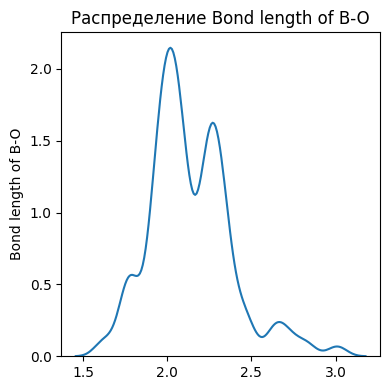

In [ ]:
#@markdown посмотрим какое распределение величины  { display-mode: "form" }
#посмотрим стандартное ли распределение
EDA.graphics.common_plt(df,"Bond length of B-O")

Распределение явно не стандартное.

С химической точки зрения длина связи может зависеть только от

1.   самих связанных атомов
2.   от окружения связанных атомов




Проверка проводится следующим образом:  

*   проверяется линейная корреляция пирсона R<sup>2</sup>
*   проверяется метод взаимной информации MI

<br>Малые показатели зависимости по этим двум параметрам позволяют судить о достаточно сильной не доказанности прямой зависимости одной величины от другой



In [ ]:
# @title
set = ('r(AVI)','Bond length of A-O',"EN(B)","EN(A)", "ionic radius of A")  # возьмем список всех величин, от которых может зависеть длина связи B-O
for i in set:
  print("\n"*3+
        "===="*15)
  print(f"check dependence of '{i}' and 'bond length of B-O'".center(75,"="))
  print(f"check linear dependence")
  print(check_undependence.check_R(df, 'Bond length of B-O',i))
  print(f"check mutual information dependence")
  check_undependence.checkMI(df, i, 'Bond length of B-O')





===========check dependence of 'r(AVI)' and 'bond length of B-O'===========
check linear dependence
0.0067
check mutual information dependence
MI = 0.06906 nats
p-value = 0.9450
NMI = 0.029



=====check dependence of 'Bond length of A-O' and 'bond length of B-O'=====
check linear dependence
0.0056
check mutual information dependence
MI = 0.05733 nats
p-value = 0.9970
NMI = 0.024



============check dependence of 'EN(B)' and 'bond length of B-O'===========
check linear dependence
0.2754
check mutual information dependence
MI = 1.38764 nats
p-value = 0.0000
NMI = 0.582



============check dependence of 'EN(A)' and 'bond length of B-O'===========
check linear dependence
0.0061
check mutual information dependence
MI = 0.08110 nats
p-value = 0.9380
NMI = 0.034



======check dependence of 'ionic radius of A' and 'bond length of B-O'=====
check linear dependence
0.0071
check mutual information dependence
MI = 0.08947 nats
p-value = 0.5850
NMI = 0.038


заметим, что при проверке зависимости нашей переменной (bond length of B-O) и электроотрицательности самого B (EN(B)) по тесту взаимной информации получается **p_val  = 0**
<br>т.е. наши данные более неупорядоченны чем случайная расстановка


---

изучим пару этих переменных подробнее подробнее.

Согласно информации из интернета, можно предполагать, что данные **кластеризованны**.
<br> Изучив датасет можно найти дискретную величину, связанную с B - это его валентность<sup>[1][2]</sup>


---
Примечания:
<br> [1] - на самом деле, в датасете указана степень окисления элемента<sup>[3]</sup>, а не валентность. их часто путают
<br> [2] - Валентность — это способность атомов химических элементов образовывать определенное число химических связей с другими атомами.  Количественной мерой валентности является **число** ковалентных **связей**, которые образует атом в молекуле.
<br> [3] - Степень окисления — это условный заряд атома в соединении.  Она численно равна количеству электронов, которые атом отдал (положительная степень) или принял (отрицательная степень) при образовании связи.


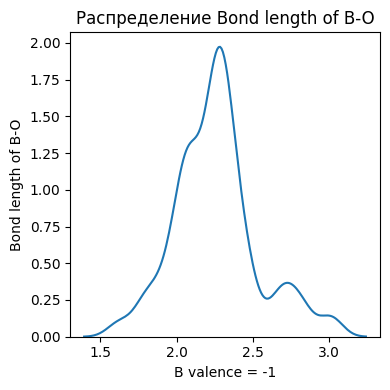

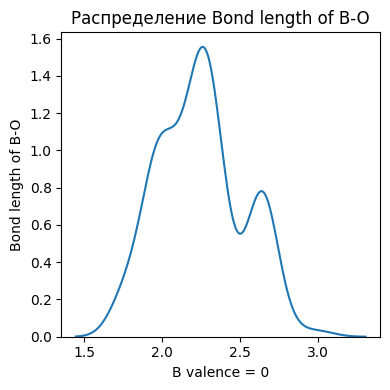

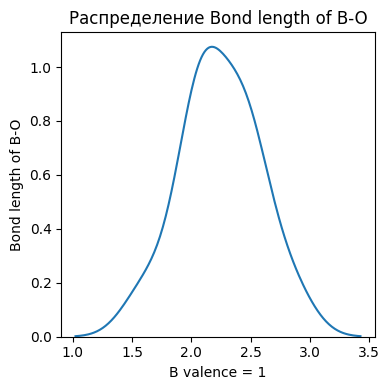

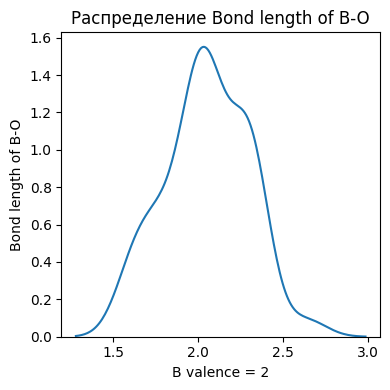

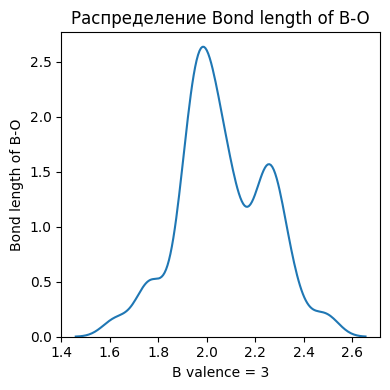

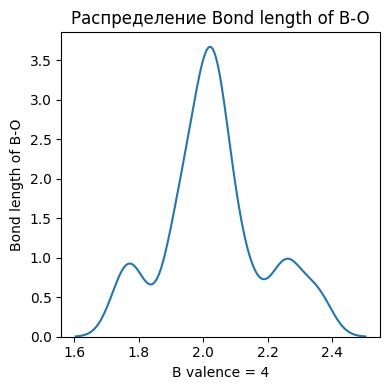

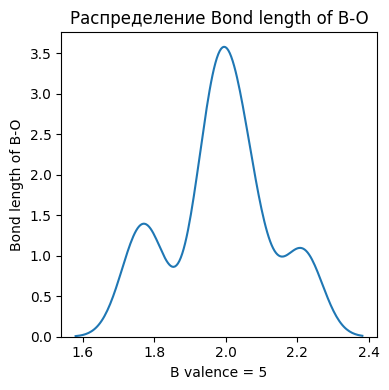

In [ ]:
# @title
for i in range(7): # степени окисления В в датасете от -1 до 5.
    graphics.common_plt(df[df["B Valence"] == i-1], 'Bond length of B-O',description="B valence = "+str(i-1))

Разбивка странная. похоже, что есть некий третий параметр.
<br> разобьем на гистограммы и посмотрим перцентили




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = -1===================================

<class 'pandas.core.series.Series'>
Index: 551 entries, 4 to 1781
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
551 non-null    float64
dtypes: float64(1)
memory usage: 8.6 KB
Количество:               551
Среднее:                  2.26
Минимум:                  1.62
Максимум:                 3.01
Стандартное отклонение:   0.27
25-й перцентиль:          2.1
50-й перцентиль:          2.26
75-й перцентиль:          2.35
95-й перцентиль:          2.83
25-й перцентиль и 50-й перцентили отстоят друг от друга на 11.6% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 06.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 34.7% от всей длины отрезка


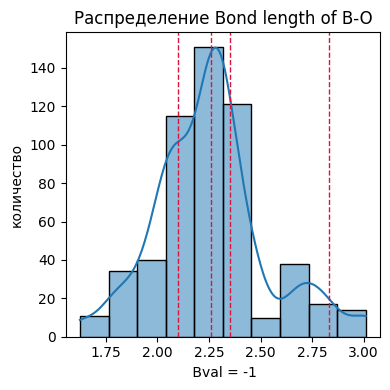




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = 0====================================

<class 'pandas.core.series.Series'>
Index: 143 entries, 21 to 1751
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
143 non-null    float64
dtypes: float64(1)
memory usage: 2.2 KB
Количество:               143
Среднее:                  2.25
Минимум:                  1.75
Максимум:                 3.01
Стандартное отклонение:   0.27
25-й перцентиль:          2.04
50-й перцентиль:          2.24
75-й перцентиль:          2.36
95-й перцентиль:          2.64
25-й перцентиль и 50-й перцентили отстоят друг от друга на 15.8% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 09.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 22.1% от всей длины отрезка


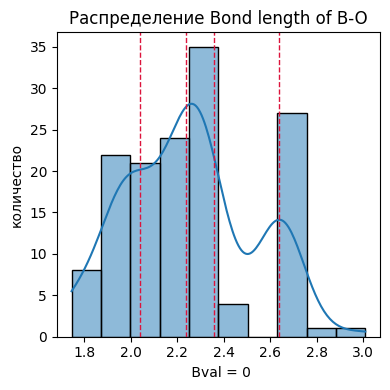




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = 1====================================

<class 'pandas.core.series.Series'>
Index: 11 entries, 136 to 1358
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
11 non-null     float64
dtypes: float64(1)
memory usage: 176.0 bytes
Количество:               11
Среднее:                  2.24
Минимум:                  1.62
Максимум:                 2.83
Стандартное отклонение:   0.32
25-й перцентиль:          2.1
50-й перцентиль:          2.1
75-й перцентиль:          2.46
95-й перцентиль:          2.66
25-й перцентиль и 50-й перцентили отстоят друг от друга на -0.0% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 30.0% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 16.6% от всей длины отрезка


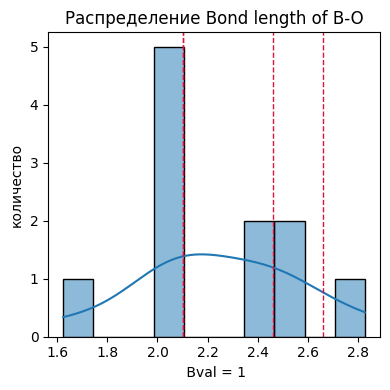




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = 2====================================

<class 'pandas.core.series.Series'>
Index: 40 entries, 116 to 1738
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
40 non-null     float64
dtypes: float64(1)
memory usage: 640.0 bytes
Количество:               40
Среднее:                  2.05
Минимум:                  1.62
Максимум:                 2.64
Стандартное отклонение:   0.24
25-й перцентиль:          1.95
50-й перцентиль:          2.04
75-й перцентиль:          2.27
95-й перцентиль:          2.32
25-й перцентиль и 50-й перцентили отстоят друг от друга на 08.9% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 22.7% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 04.9% от всей длины отрезка


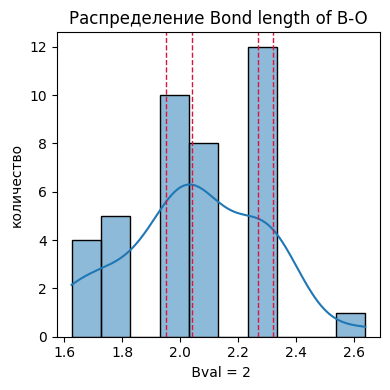




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = 3====================================

<class 'pandas.core.series.Series'>
Index: 372 entries, 3 to 1785
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
372 non-null    float64
dtypes: float64(1)
memory usage: 5.8 KB
Количество:               372
Среднее:                  2.07
Минимум:                  1.62
Максимум:                 2.49
Стандартное отклонение:   0.18
25-й перцентиль:          1.96
50-й перцентиль:          2.03
75-й перцентиль:          2.24
95-й перцентиль:          2.35
25-й перцентиль и 50-й перцентили отстоят друг от друга на 08.1% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 24.3% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 12.7% от всей длины отрезка


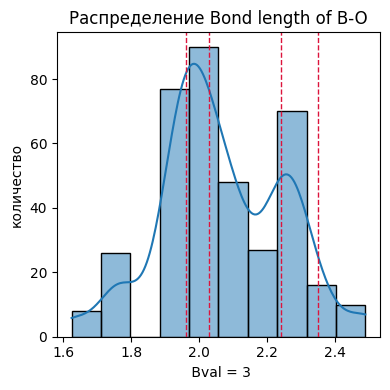




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = 4====================================

<class 'pandas.core.series.Series'>
Index: 361 entries, 0 to 1778
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
361 non-null    float64
dtypes: float64(1)
memory usage: 5.6 KB
Количество:               361
Среднее:                  2.03
Минимум:                  1.75
Максимум:                 2.36
Стандартное отклонение:   0.15
25-й перцентиль:          1.96
50-й перцентиль:          2.03
75-й перцентиль:          2.12
95-й перцентиль:          2.34
25-й перцентиль и 50-й перцентили отстоят друг от друга на 11.3% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 14.6% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 35.6% от всей длины отрезка


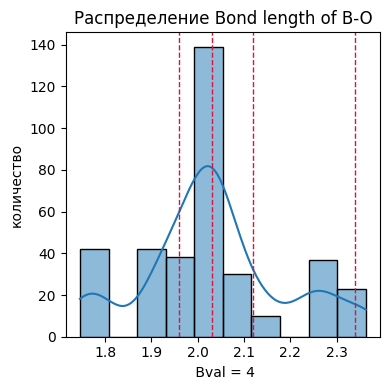




==================== начинаем анализ по Bond length of B-O =====================
=================================== Bval = 5====================================

<class 'pandas.core.series.Series'>
Index: 97 entries, 36 to 1782
Series name: Bond length of B-O
Non-Null Count  Dtype  
--------------  -----  
97 non-null     float64
dtypes: float64(1)
memory usage: 1.5 KB
Количество:               97
Среднее:                  1.99
Минимум:                  1.75
Максимум:                 2.22
Стандартное отклонение:   0.14
25-й перцентиль:          1.96
50-й перцентиль:          1.99
75-й перцентиль:          2.05
95-й перцентиль:          2.22
25-й перцентиль и 50-й перцентили отстоят друг от друга на 06.4% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 12.8% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 36.2% от всей длины отрезка


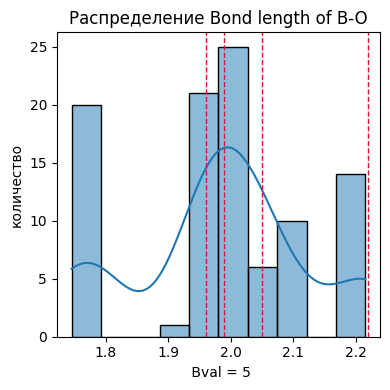

In [ ]:
# @title
for i in range(7):
    EDA.EDA_one_param(df[df["B Valence"] == i-1], 'Bond length of B-O',description=(" Bval = "+str(i-1)))

Заметим следующее:


*   Перцентили расположены неравномерно(либо очень близко или далеко)
*   Явно не нормальное распределение
*   Перцентили склонны быть в районе пиков

<br> Из этого делаем вывод, что **данные кластеризованны**.




Из кластеризации данных мы можем сделать вывод, что каждая из валентностей содержит по N нормальных распределений.
<br><br>Для мультинормальных распределений в Python есть библиотека sklearn.mixture в которой есть метод GaussianMixture. которым мы воспользуемся для определения числа компонент через **BIC**.

In [ ]:
# @title
for i in range(-1,6):  #переберём валентности
    math_model.bic_in_multinormal_model(df[df["B Valence"] == i], 'Bond length of B-O',description=f"B Valence = {str(i)}")

=================================B Valence = -1=================================

components=1: BIC = 137.54
components=2: BIC = 100.11
components=3: BIC = 60.53
components=4: BIC = 16.89
components=5: BIC = -34.42
components=6: BIC = -32.34
components=7: BIC = -41.58
components=8: BIC = -92.93
components=9: BIC = -336.31
=================================B Valence = 0==================================

components=1: BIC = 38.19
components=2: BIC = -163.74
components=3: BIC = 12.40
components=4: BIC = 11.92
components=5: BIC = 21.65
components=6: BIC = 4.77
components=7: BIC = -56.15
components=8: BIC = -15.39
components=9: BIC = -47.68
=================================B Valence = 1==================================

components=1: BIC = 10.18
components=2: BIC = 17.45
components=3: BIC = 4.16
components=4: BIC = -7.17
components=5: BIC = -21.94
components=6: BIC = -40.74
components=7: BIC = -43.18
components=8: BIC = -35.99
components=9: BIC = -28.79
=================================B V

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (7) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (7) found smaller than n_clusters (9). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


components=5: BIC = -258.83
components=6: BIC = -250.36
components=7: BIC = -245.27
components=8: BIC = -406.74
components=9: BIC = -454.91
=================================B Valence = 4==================================

components=1: BIC = -326.24
components=2: BIC = -356.56
components=3: BIC = -479.57
components=4: BIC = -483.18
components=5: BIC = -504.05
components=6: BIC = -604.46
components=7: BIC = -674.74
components=8: BIC = -730.25
components=9: BIC = -785.04
=================================B Valence = 5==================================

components=1: BIC = -100.67
components=2: BIC = -128.20
components=3: BIC = -270.96
components=4: BIC = -321.01
components=5: BIC = -294.10
components=6: BIC = -319.24
components=7: BIC = -333.31
components=8: BIC = -387.64
components=9: BIC = -426.89


Принцип выбора числа компонент по BIC:


*   Выбираем падение BIC
*   Если BIC монотонно убывает, то выбираем самое большое падение

<br> Таким образом, приходим к следующим результатам:

<br>валентность : число компонент
<br>-1: 5
<br>0 :  3
<br>1 :  6
<br>2 :  6
<br>3 :  5
<br>4 :  3
<br>5 :  4






In [ ]:
# @title
bic_res_BO={-1:5,
            0 :3,
            1 :6,
            2 :6,
            3 :5,
            4 :3,
            5 :4}





=========== начинаем мультимодальный анализ для числа компонент = 5 ============
===================================Bval = -1====================================

Средние компонент: [2.45, 2.07, 2.78, 1.88, 2.28]
Дисперсии: [0.0, 0.0, 0.02, 0.02, 0.0]
Веса: [0.08, 0.21, 0.13, 0.14, 0.43]


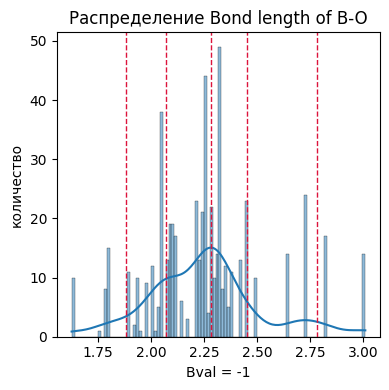





=========== начинаем мультимодальный анализ для числа компонент = 3 ============
====================================Bval = 0====================================

Средние компонент: [2.28, 2.65, 1.98]
Дисперсии: [0.0, 0.01, 0.01]
Веса: [0.39, 0.22, 0.39]


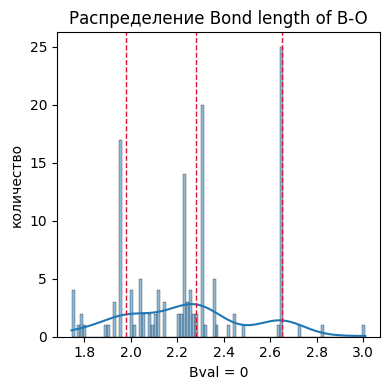





=========== начинаем мультимодальный анализ для числа компонент = 6 ============
====================================Bval = 1====================================

Средние компонент: [2.1, 2.49, 1.62, 2.83, 2.01, 2.43]
Дисперсии: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Веса: [0.36, 0.18, 0.09, 0.09, 0.09, 0.18]


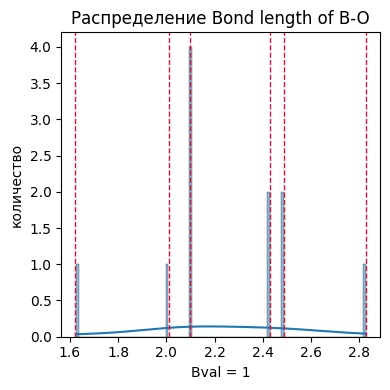





=========== начинаем мультимодальный анализ для числа компонент = 6 ============
====================================Bval = 2====================================

Средние компонент: [2.1, 1.62, 2.3, 2.0, 2.64, 1.78]
Дисперсии: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Веса: [0.1, 0.1, 0.3, 0.35, 0.03, 0.12]


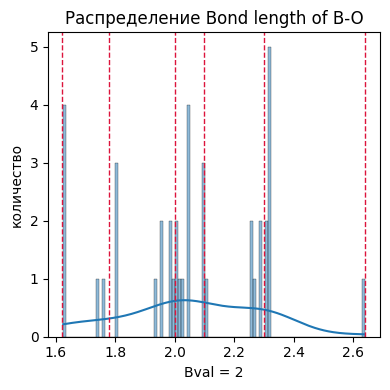





=========== начинаем мультимодальный анализ для числа компонент = 5 ============
====================================Bval = 3====================================

Средние компонент: [2.06, 2.44, 1.95, 1.74, 2.26]
Дисперсии: [0.0, 0.0, 0.0, 0.0, 0.0]
Веса: [0.32, 0.04, 0.29, 0.09, 0.25]


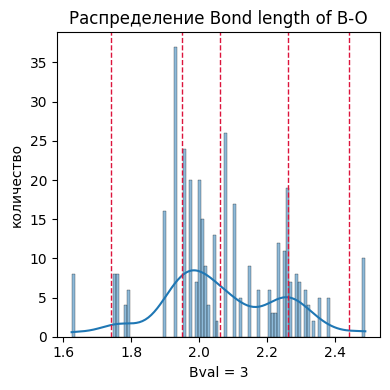





=========== начинаем мультимодальный анализ для числа компонент = 3 ============
====================================Bval = 4====================================

Средние компонент: [2.28, 2.01, 1.77]
Дисперсии: [0.0, 0.0, 0.0]
Веса: [0.18, 0.7, 0.12]


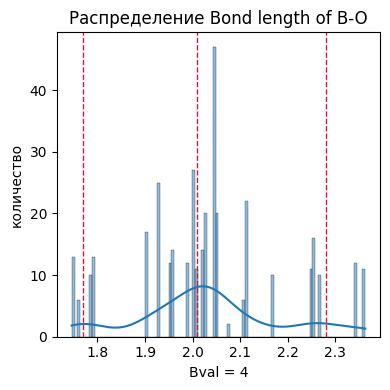





=========== начинаем мультимодальный анализ для числа компонент = 4 ============
====================================Bval = 5====================================

Средние компонент: [1.77, 2.03, 2.22, 1.96]
Дисперсии: [0.0, 0.0, 0.0, 0.0]
Веса: [0.21, 0.44, 0.14, 0.21]


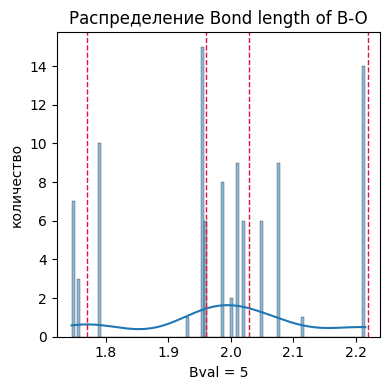

In [ ]:
# @title
for val,comp in bic_res_BO.items():
    math_model.check_multinormal_model(df[df["B Valence"] == val],param='Bond length of B-O',components=comp,
                                       autoBIC=False,description=f"Bval = {val}", bins = 100)# примечание: рекомендуется попробовать поизменять параметр bins. без указания параметра по умолчанию = 20.
                                       # рекомендуется попробовать выставить bins = 50, 100

Из за чего могут быть кластеры?
<br> Причина проста. обратимся еще раз к определению перовскитов(ведь именно им посвящен датасет):
<br><br>Перовскиты — **класс** хим соединений, объединенных схожей кристаллической структурой
<br><br>Итак, кластеризация обьясняется тем, что в соединениях просто находятся разные атомы. Т.к. разные атомы имеют:


*   Разную электроотрицательность
*   Разный радиус

Итак, мы изучили природу неоднородности распределения.
<br> *Далее рассмотрим только такие длины связей, где степень окисления B равна -1*


---

примечание: некоторые валентности имеют очень малое число записей (см графики) приходится выбирать наиболее наполненные.
<br> рекомендуется в целях изучения датасета поизменять current valence ниже и посмотреть, как будут вести себя значения и числа



,A Valence,B Valence,ionic radius of A,r(AVI),r(BVI),EN(A),EN(B),Bond length of A-O,Bond length of B-O,ΔENR,tG,τ,μ
4,-1,-1,0.89,0.72,0.86,1.31,1.27,2.401381,2.209115,-2.400536,0.716493,0.0,0.614286
5,-1,-1,0.90,0.74,0.52,1.65,2.18,2.375479,1.932227,-1.376286,0.847055,0.0,0.371429
7,-1,-1,1.38,0.90,1.67,2.02,0.79,2.514402,3.009747,-4.204714,0.640312,0.0,1.192857
8,-1,-1,1.70,1.20,0.96,1.62,1.25,2.531967,2.119701,-3.133071,0.928827,0.0,0.685714
10,-1,-1,0.68,0.68,0.95,1.90,1.10,2.301548,2.223981,-2.257929,0.625865,0.0,0.678571
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1773,-1,-1,0.68,0.68,0.45,2.05,1.57,2.361079,1.803349,-1.230393,0.795017,0.0,0.321429
1776,-1,-1,0.81,0.69,0.74,1.96,1.65,2.342369,2.096141,-1.818107,0.730236,0.0,0.528571
1777,-1,-1,0.96,0.62,0.95,1.55,1.93,2.472899,2.488353,-2.326107,0.710116,0.0,0.678571
1779,-1,-1,0.62,0.62,0.99,1.81,1.22,2.233188,2.255581,-2.284179,0.597638,0.0,0.707143


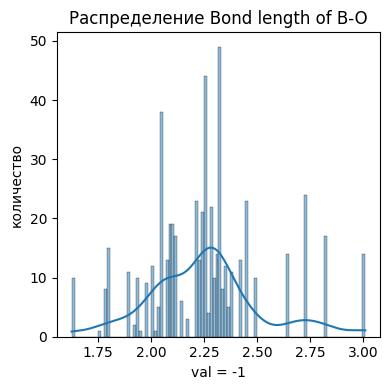

In [ ]:
# @title
current_valence = -1
df_B_VAL = df[df["B Valence"] == current_valence]
display(df_B_VAL)
#помним, что это все еще кластеры
# валентности A и B нередко совпадают
graphics.make_histplot(df_B_VAL,'Bond length of B-O',description=f"val = {current_valence}",bins=100)

Обратим внимание на график сверху.
<br>При большом количестве бинов оказывается, что данные куда сильнее кластеризованны. есть много маленьких подкластеров.
<br>

1.   выполним расширенный анализ BIC для большого числа компонент 25, например
2.   потом построим для трех самых больших разрывов по графику и посмотрим, как компьютер размечает



In [ ]:
# @title
BIC_res_for_B_VAL = math_model.bic_in_multinormal_model(df_B_VAL,'Bond length of B-O',description=f"B Valence = {str(-1)}",search_range=25,giveDiff=True)

=================================B Valence = -1=================================

components=1: BIC = 137.54
components=2: BIC = 100.11     ∆BIC = 37.43
components=3: BIC = 60.53     ∆BIC = 39.58
components=4: BIC = 16.89     ∆BIC = 43.64
components=5: BIC = -34.42     ∆BIC = 51.31
components=6: BIC = -32.34     ∆BIC = -2.08
components=7: BIC = -41.58     ∆BIC = 9.24
components=8: BIC = -92.93     ∆BIC = 51.35
components=9: BIC = -336.31     ∆BIC = 243.38
components=10: BIC = -376.42     ∆BIC = 40.11
components=11: BIC = -379.45     ∆BIC = 3.03
components=12: BIC = -380.90     ∆BIC = 1.45
components=13: BIC = -630.75     ∆BIC = 249.85
components=14: BIC = -672.72     ∆BIC = 41.97
components=15: BIC = -728.92     ∆BIC = 56.20
components=16: BIC = -849.08     ∆BIC = 120.16
components=17: BIC = -775.44     ∆BIC = -73.64
components=18: BIC = -805.65     ∆BIC = 30.21
components=19: BIC = -960.48     ∆BIC = 154.83
components=20: BIC = -988.21     ∆BIC = 27.73
components=21: BIC = -864.13    

In [ ]:
# @title
BIC_differences = []
for i in list(BIC_res_for_B_VAL.values()):
  BIC_differences.append(abs(i[1]))






=========== начинаем мультимодальный анализ для числа компонент = 13 ===========
====================================Bval = 5====================================

Средние компонент: [2.45, 2.03, 2.83, 2.31, 1.62, 1.92, 2.64, 2.1, 3.01, 1.8, 2.24, 2.36, 2.72]
Дисперсии: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Веса: [0.08, 0.12, 0.03, 0.17, 0.02, 0.04, 0.03, 0.13, 0.03, 0.04, 0.21, 0.05, 0.04]


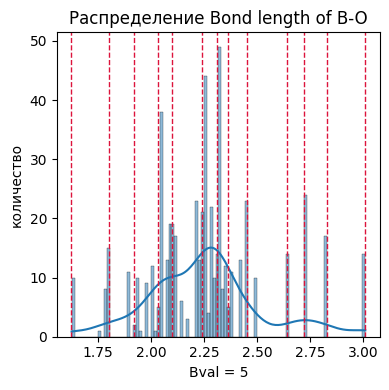





=========== начинаем мультимодальный анализ для числа компонент = 9 ============
====================================Bval = 5====================================

Средние компонент: [2.45, 2.04, 2.83, 2.28, 1.62, 1.88, 2.69, 2.1, 3.01]
Дисперсии: [0.0, 0.0, 0.0, 0.0, 0.0, 0.01, 0.0, 0.0, 0.0]
Веса: [0.08, 0.12, 0.03, 0.44, 0.02, 0.1, 0.07, 0.11, 0.03]


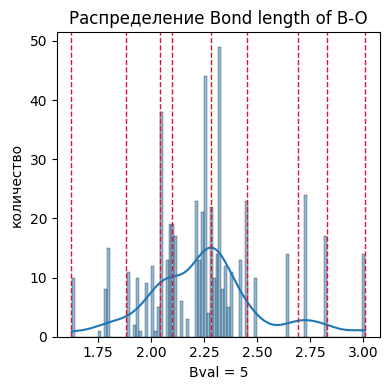





=========== начинаем мультимодальный анализ для числа компонент = 22 ===========
====================================Bval = 5====================================

Средние компонент: [2.43, 2.01, 3.01, 2.24, 2.72, 1.8, 2.32, 2.1, 1.62, 1.93, 2.83, 2.64, 2.36, 2.45, 2.16, 1.97, 2.25, 2.29, 1.9, 2.05, 2.22, 2.49]
Дисперсии: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Веса: [0.02, 0.03, 0.03, 0.02, 0.04, 0.04, 0.11, 0.12, 0.02, 0.02, 0.03, 0.03, 0.07, 0.04, 0.02, 0.02, 0.11, 0.06, 0.02, 0.07, 0.07, 0.02]


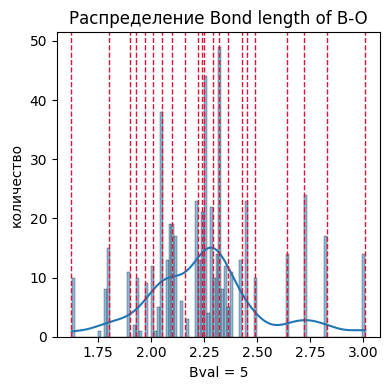

In [ ]:
# @title

for i in range(3):
  comp = list(BIC_res_for_B_VAL.keys())[BIC_differences.index(max(BIC_differences))]
  BIC_differences[BIC_differences.index(max(BIC_differences))]=0
  math_model.check_multinormal_model(df[df["B Valence"] == current_valence],param='Bond length of B-O',components=comp,
                                       autoBIC=False,description=f"Bval = {val}", bins = 100)

Далее возьмем число компонент за 13, т.к. покрываются наиболее заметные дискретные пики. более того, разность BIC при 13 компоненте самая большая.

In [ ]:
# @title
testB = df_B_VAL[df_B_VAL['Bond length of B-O']>1.781]
testB = testB[testB['Bond length of B-O']<1.785]
testB
#graphics.make_histplot(testB,'Bond length of B-O',description=f"val = {current_valence}",bins=20)

,A Valence,B Valence,ionic radius of A,r(AVI),r(BVI),EN(A),EN(B),Bond length of A-O,Bond length of B-O,ΔENR,tG,τ,μ
394,-1,-1,1.88,1.67,0.4,0.79,1.9,3.300176,1.783361,-1.904000,1.288506,0.0,0.285714
442,-1,-1,0.40,0.40,0.4,1.90,1.9,2.082801,1.783361,-0.931429,0.707107,0.0,0.285714
608,-1,-1,0.57,0.57,0.4,1.90,1.9,2.339396,1.783361,-1.024929,0.773889,0.0,0.285714
1098,-1,-1,1.61,1.35,0.4,0.89,1.9,2.942999,1.783361,-1.741214,1.182440,0.0,0.285714
1118,-1,-1,0.73,0.62,0.4,2.16,1.9,2.079036,1.783361,-1.075786,0.836743,0.0,0.285714
1191,-1,-1,1.39,1.02,0.4,0.93,1.9,2.759925,1.783361,-1.614500,1.096016,0.0,0.285714


Также заметим, что степени окисления А и В совпадают. проверим их независимость

In [ ]:
# @title
check_undependence.checkMI(df_B_VAL, "B Valence", "A Valence")

MI = 0.00000 nats
p-value = 1.0000
NMI = nan


/usr/local/lib/python3.13/dist-packages/statistics_project/check_undependence.py:95: RuntimeWarning: invalid value encountered in scalar divide
  nmi = mi / min(h_x, h_y)


Видим, что степени окисления А и В абсолютно детерминированны.
<br>Однако мы помним, что длина связи B-O и A-O независимы (см выше)
<br>**ВОЗЬМЕМ В КАЧЕСТВЕ ВТОРОЙ ПЕРЕМЕННОЙ ДЛИНУ СВЯЗИ А-О**

<br><br><br><br><br>

---


# [3.2] независимая переменная №2


---



In [ ]:
# @title
set = ('r(AVI)','Bond length of B-O','Bond length of A-O',"EN(B)","EN(A)", "ionic radius of A","A Valence")  # возьмем список всех величин, от которых может зависеть длина связи B-O

for i in set:
  print("\n"*3+
        "===="*15)
  print(f"check dependence of '{i}' and 'bond length of A-O'".center(75,"="))
  print(f"check linear dependence")
  print(check_undependence.check_R(df, 'Bond length of A-O',i))
  print(f"check mutual information dependence")
  check_undependence.checkMI(df, i, 'Bond length of A-O')





===========check dependence of 'r(AVI)' and 'bond length of A-O'===========
check linear dependence
0.878
check mutual information dependence
MI = 1.40006 nats
p-value = 0.0000
NMI = 0.595



=====check dependence of 'Bond length of B-O' and 'bond length of A-O'=====
check linear dependence
0.0056
check mutual information dependence
MI = 0.05733 nats
p-value = 0.9870
NMI = 0.024



=====check dependence of 'Bond length of A-O' and 'bond length of A-O'=====
check linear dependence
1.0
check mutual information dependence
MI = 2.41299 nats
p-value = 0.0000
NMI = 1.000



============check dependence of 'EN(B)' and 'bond length of A-O'===========
check linear dependence
0.0028
check mutual information dependence
MI = 0.06452 nats
p-value = 1.0000
NMI = 0.027



============check dependence of 'EN(A)' and 'bond length of A-O'===========
check linear dependence
0.38
check mutual information dependence
MI = 1.37482 nats
p-value = 0.0000
NMI = 0.570



======check dependence of 'ionic radiu

<br><br>

с химической точки зрения, переменная длины связи А-О связана с:


1.   Электроотрицательностью А
2.   С ионным радиусом А<sup>[1]</sup>
3.   Степенью окисления

<br> полученные результаты в тестах согласуются с химической логикой<sup>[2]</sup>

---
[1] - согласно тестам, длина А-О зависит от r(AVI), ionic radius of A и от EN(A). первые две характеристики являются синонимичными, но не эквивалентными.
<br>

*   ионный радиус А - это буквально радиус иона А
*   r(AVI) это радиус иона А в гексагональном окружении (т.е. в таком, в которым 6 некоторых отличных от А,В или О частиц окружают А)
<br> r(AVI) будет всегда несколько меньше обычного ионного радиуса А. далее мы их будем считать эквивалентными в контексте связанности и влияния на длину свзи А-О
<br><br>[2] - заметим, что степень окисления(подписанная как валентность) снова не показывает большой степени связи по тесту взаимной информации, но p - значение нулевое, что говорит о такой же кластеризации.




<br>
также быстро покажем сначла кластеризацию А

In [ ]:
# @title
df['A Valence'].unique()

array([ 2,  3, -1,  0,  1,  4,  5])




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = -1===================================

<class 'pandas.core.series.Series'>
Index: 551 entries, 4 to 1781
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
551 non-null    float64
dtypes: float64(1)
memory usage: 8.6 KB
Количество:               551
Среднее:                  2.5
Минимум:                  1.89
Максимум:                 3.3
Стандартное отклонение:   0.28
25-й перцентиль:          2.32
50-й перцентиль:          2.42
75-й перцентиль:          2.65
95-й перцентиль:          3.03
25-й перцентиль и 50-й перцентили отстоят друг от друга на 07.1% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 16.3% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 27.0% от всей длины отрезка


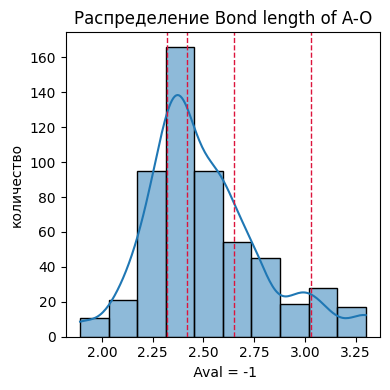

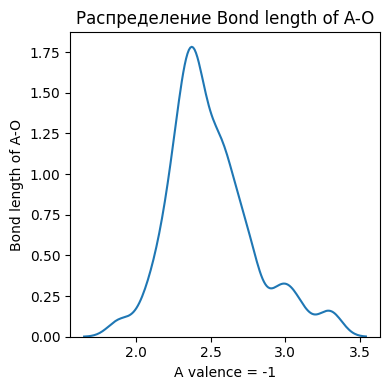




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = 0====================================

<class 'pandas.core.series.Series'>
Index: 143 entries, 21 to 1751
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
143 non-null    float64
dtypes: float64(1)
memory usage: 2.2 KB
Количество:               143
Среднее:                  2.45
Минимум:                  2.06
Максимум:                 3.3
Стандартное отклонение:   0.19
25-й перцентиль:          2.3
50-й перцентиль:          2.42
75-й перцентиль:          2.56
95-й перцентиль:          2.76
25-й перцентиль и 50-й перцентили отстоят друг от друга на 09.7% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 11.3% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 16.2% от всей длины отрезка


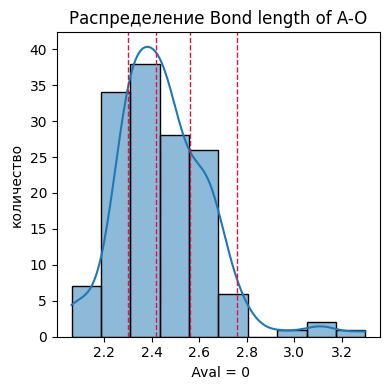

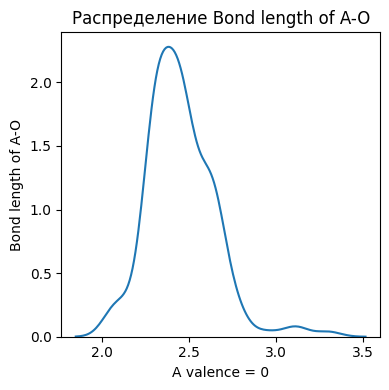




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = 1====================================

<class 'pandas.core.series.Series'>
Index: 97 entries, 36 to 1782
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
97 non-null     float64
dtypes: float64(1)
memory usage: 1.5 KB
Количество:               97
Среднее:                  2.57
Минимум:                  1.89
Максимум:                 3.3
Стандартное отклонение:   0.31
25-й перцентиль:          2.38
50-й перцентиль:          2.51
75-й перцентиль:          2.76
95-й перцентиль:          3.11
25-й перцентиль и 50-й перцентили отстоят друг от друга на 09.2% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 17.7% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 24.8% от всей длины отрезка


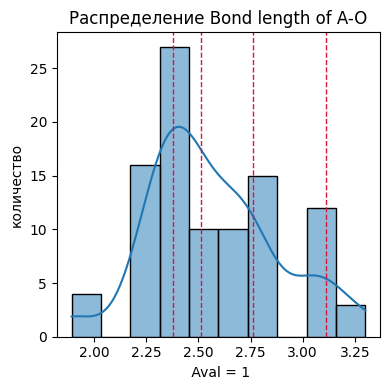

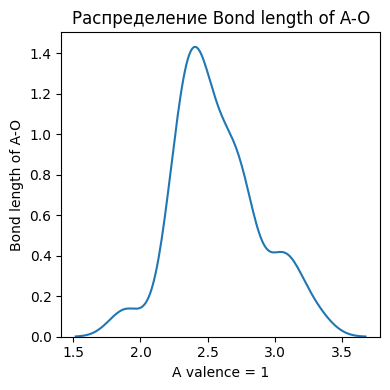




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = 2====================================

<class 'pandas.core.series.Series'>
Index: 361 entries, 0 to 1778
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
361 non-null    float64
dtypes: float64(1)
memory usage: 5.6 KB
Количество:               361
Среднее:                  2.47
Минимум:                  1.89
Максимум:                 2.94
Стандартное отклонение:   0.21
25-й перцентиль:          2.3
50-й перцентиль:          2.51
75-й перцентиль:          2.62
95-й перцентиль:          2.77
25-й перцентиль и 50-й перцентили отстоят друг от друга на 20.0% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 10.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 14.3% от всей длины отрезка


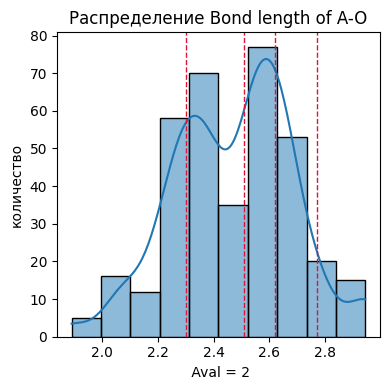

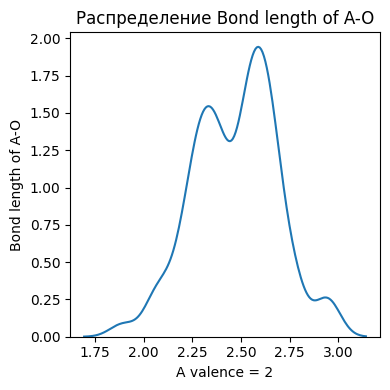




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = 3====================================

<class 'pandas.core.series.Series'>
Index: 372 entries, 3 to 1785
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
372 non-null    float64
dtypes: float64(1)
memory usage: 5.8 KB
Количество:               372
Среднее:                  2.46
Минимум:                  2.08
Максимум:                 2.69
Стандартное отклонение:   0.17
25-й перцентиль:          2.34
50-й перцентиль:          2.52
75-й перцентиль:          2.58
95-й перцентиль:          2.69
25-й перцентиль и 50-й перцентили отстоят друг от друга на 29.5% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 09.8% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 18.0% от всей длины отрезка


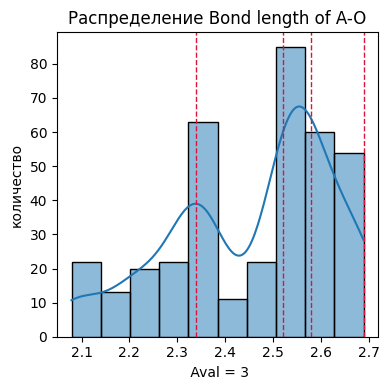

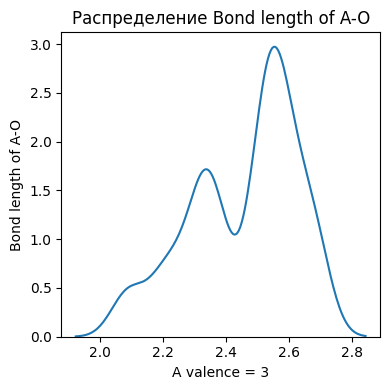




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = 4====================================

<class 'pandas.core.series.Series'>
Index: 40 entries, 116 to 1738
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
40 non-null     float64
dtypes: float64(1)
memory usage: 640.0 bytes
Количество:               40
Среднее:                  2.43
Минимум:                  2.08
Максимум:                 2.66
Стандартное отклонение:   0.18
25-й перцентиль:          2.34
50-й перцентиль:          2.47
75-й перцентиль:          2.58
95-й перцентиль:          2.59
25-й перцентиль и 50-й перцентили отстоят друг от друга на 22.4% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 18.9% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 01.7% от всей длины отрезка


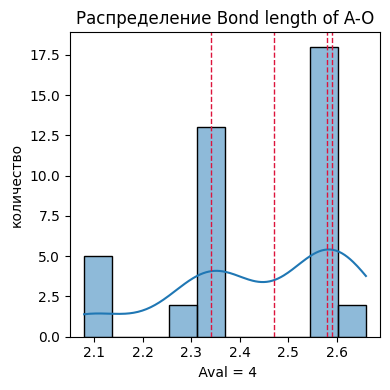

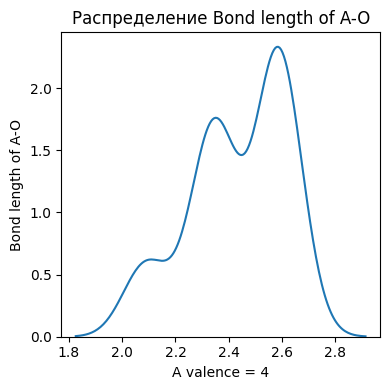




==================== начинаем анализ по Bond length of A-O =====================
=================================== Aval = 5====================================

<class 'pandas.core.series.Series'>
Index: 11 entries, 136 to 1358
Series name: Bond length of A-O
Non-Null Count  Dtype  
--------------  -----  
11 non-null     float64
dtypes: float64(1)
memory usage: 176.0 bytes
Количество:               11
Среднее:                  2.31
Минимум:                  2.26
Максимум:                 2.34
Стандартное отклонение:   0.03
25-й перцентиль:          2.31
50-й перцентиль:          2.32
75-й перцентиль:          2.34
95-й перцентиль:          2.34
25-й перцентиль и 50-й перцентили отстоят друг от друга на 11.6% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 23.2% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на -0.0% от всей длины отрезка


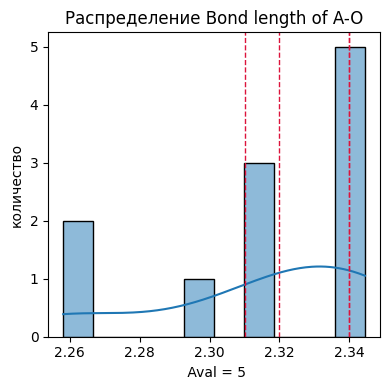

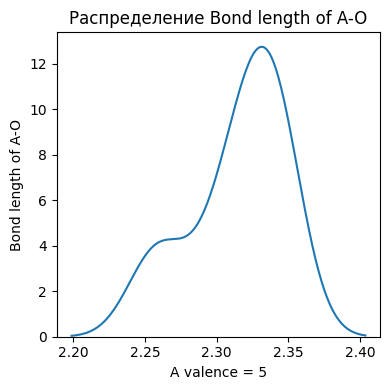

In [ ]:
# @markdown   пробежимся по валентностям А
for i in range(7): # буквально тот же самый метод из B
    EDA.EDA_one_param(df[df["A Valence"] == i-1],'Bond length of A-O',description=(" Aval = "+str(i-1)))
    #graphics.common_plt(df[df["A Valence"] == i-1], 'Bond length of A-O',description="A valence = "+str(i-1))
#перцентили также пляшут, видна кластеризация.

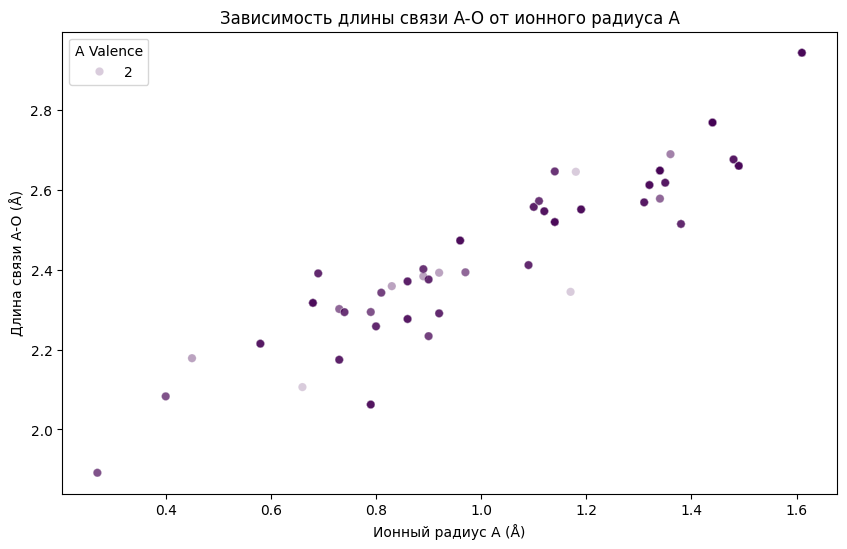

In [ ]:
# @markdown   распределение записей по ионному радиусу и длине связи А
import matplotlib.pyplot as plt # здесь и далее блеклые точки - единичное наблюдение, а насыщенные - множество наложившихся единичных
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[df["A Valence"]== 2], x='ionic radius of A', y='Bond length of A-O', hue='A Valence',
                 palette='viridis', alpha=0.2)
plt.title('Зависимость длины связи A-O от ионного радиуса A')
plt.xlabel('Ионный радиус A (Å)')
plt.ylabel('Длина связи A-O (Å)')

plt.show()

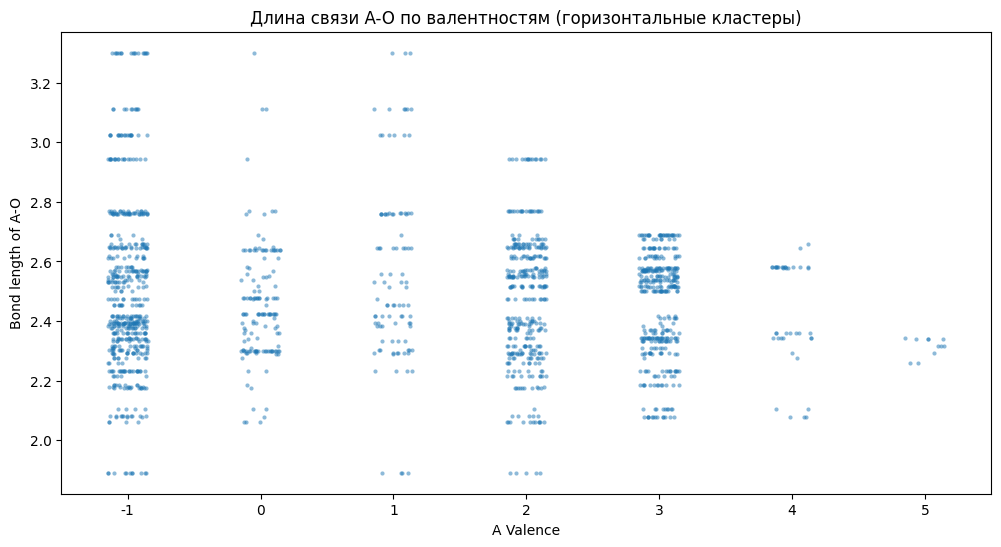

In [ ]:
# @markdown   взглянем на распределение записей  по валентносятм и длине связей

plt.figure(figsize=(12, 6))
# jitter  раздвигает точки, чтобы они не слипались
sns.stripplot(data=df, x='A Valence', y='Bond length of A-O',
              jitter=0.15, alpha=0.5, size=3)
plt.title('Длина связи A-O по валентностям (горизонтальные кластеры)')
plt.show()

плавные градиентные вертикальные столбцы должны быть! а их тут нет. очень четкие константы

In [ ]:
# @title


groups = [group['Bond length of A-O'].dropna().values
          for name, group in df.groupby('A Valence')]

# Тест Краскела-Уоллиса
h_stat, p_value = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H = {h_stat:.4f}, p-value = {p_value:.4g}")

if p_value < 0.05:
    print("Различия между валентностями значимы.")
else:
    print("Нет оснований считать, что распределения различаются.")

Kruskal-Wallis: H = 19.0895, p-value = 0.004015
Различия между валентностями статистически значимы.


In [ ]:
# @title

rho, p = spearmanr(df['Bond length of A-O'], df['EN(A)'])
print(f"Spearman: rho = {rho:.3f}, p = {p:.2e}")

Spearman: rho = -0.647, p = 9.78e-188


между электроотрицательностью и длиной связи есть стопроцентная отрицательная связь (по спирмену), т.к. p- значение равно нулю ( ну или примерно 10<sup>-187</sup>)

Более того, группы действительно разные, а не из за случайного распределения, что подтверждается тестом крускаля уоллиса

# [4]Выводы по датасету 1(в разработке)

Как оказалось, длины связи между двумя определенными атомами константны вне зависимости от окружения и соседей. более того, при одном типе кристаллической решетки они не зависят от температур.
<br>

---

Примечание: разные температуры приготовления соединения могут давать разные типы взаимных расположений атомов(т.н. решетки).
<br> в описании датасета указано, что решетки в нем разные, т.е. часть констант могут принадлежать одному элементу но в разных типах решеток

# Второй датасет

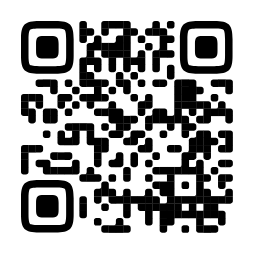
https://clck.ru/3WoGxG

In [3]:
# @markdown   импорты
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

In [4]:
# @markdown   подключение к kaggle для подгрузки датасета
import kagglehub

path = kagglehub.dataset_download("utsavdey1410/food-nutrition-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'food-nutrition-dataset' dataset.
Path to dataset files: /kaggle/input/food-nutrition-dataset


In [5]:
# @markdown   подключение датасета
for root, dirs, files in os.walk(path):
    level = root.replace(str(path), '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f'{subindent}{f}')

food-nutrition-dataset/
    FINAL FOOD DATASET/
        FOOD-DATA-GROUP5.csv
        FOOD-DATA-GROUP4.csv
        FOOD-DATA-GROUP1.csv
        FOOD-DATA-GROUP3.csv
        FOOD-DATA-GROUP2.csv
        METADATA/
            GROUP-2_analysis_summary.csv
            GROUP-4_analysis_summary.csv
            Combined_FOOD_METADATA.csv
            GROUP-3_analysis_summary.csv
            GROUP-1_analysis_summary.csv
            GROUP-5_analysis_summary.csv
        DATASET/
            GROUP-1_Histogram_of_Protein.png
            GROUP-1_Description.csv
            GROUP-3_Histogram_of_Protein.png
            GROUP-1_Histogram_of_Carbohydrates.png
            GROUP-3_Histogram_of_Dietary Fiber.png
            GROUP-4_Histogram_of_Protein.png
            GROUP-2_Description.csv
            GROUP-5_Histogram_of_Dietary Fiber.png
            GROUP-1_Histogram_of_Dietary Fiber.png
            GROUP-1_Histogram_of_Caloric Value.png
            GROUP-3_Histogram_of_Carbohydrates.png
            GRO

In [6]:
# @markdown   Работа с папками и файлами
df1 = pd.read_csv(os.path.join(str(path)+"/FINAL FOOD DATASET/", 'FOOD-DATA-GROUP1.csv'))
df2 = pd.read_csv(os.path.join(str(path)+"/FINAL FOOD DATASET/", 'FOOD-DATA-GROUP2.csv'))
df3 = pd.read_csv(os.path.join(str(path)+"/FINAL FOOD DATASET/", 'FOOD-DATA-GROUP3.csv'))
df4 = pd.read_csv(os.path.join(str(path)+"/FINAL FOOD DATASET/", 'FOOD-DATA-GROUP4.csv'))
df5 = pd.read_csv(os.path.join(str(path)+"/FINAL FOOD DATASET/", 'FOOD-DATA-GROUP5.csv'))
df = pd.concat([df1, df2, df3, df4], ignore_index=True)
df.shape

(1673, 37)

In [7]:
# @title
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'food', 'Caloric Value', 'Fat',
       'Saturated Fats', 'Monounsaturated Fats', 'Polyunsaturated Fats',
       'Carbohydrates', 'Sugars', 'Protein', 'Dietary Fiber', 'Cholesterol',
       'Sodium', 'Water', 'Vitamin A', 'Vitamin B1', 'Vitamin B11',
       'Vitamin B12', 'Vitamin B2', 'Vitamin B3', 'Vitamin B5', 'Vitamin B6',
       'Vitamin C', 'Vitamin D', 'Vitamin E', 'Vitamin K', 'Calcium', 'Copper',
       'Iron', 'Magnesium', 'Manganese', 'Phosphorus', 'Potassium', 'Selenium',
       'Zinc', 'Nutrition Density'],
      dtype='object')

In [8]:
# @title
df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"], axis=1, inplace=True)

In [9]:
# @title
print(df.duplicated().sum())
print(df.shape[0] - df["food"].nunique())

0
0


In [10]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1673 entries, 0 to 1672
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   food                  1673 non-null   object 
 1   Caloric Value         1673 non-null   int64  
 2   Fat                   1673 non-null   float64
 3   Saturated Fats        1673 non-null   float64
 4   Monounsaturated Fats  1673 non-null   float64
 5   Polyunsaturated Fats  1673 non-null   float64
 6   Carbohydrates         1673 non-null   float64
 7   Sugars                1673 non-null   float64
 8   Protein               1673 non-null   float64
 9   Dietary Fiber         1673 non-null   float64
 10  Cholesterol           1673 non-null   float64
 11  Sodium                1673 non-null   float64
 12  Water                 1673 non-null   float64
 13  Vitamin A             1673 non-null   float64
 14  Vitamin B1            1673 non-null   float64
 15  Vitamin B11          

In [11]:
# @markdown увидеть датасет воочию
df.head(2)

,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,Protein,Dietary Fiber,...,Calcium,Copper,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density
0,cream cheese,51,5.0,2.9,1.3,0.2,0.8,0.5,0.9,0.0,...,0.008,14.100,0.082,0.027,1.300,0.091,15.5,19.100,0.039,7.07
1,neufchatel cheese,215,19.4,10.9,4.9,0.8,3.1,2.7,7.8,0.0,...,99.500,0.034,0.100,8.500,0.088,117.300,129.2,0.054,0.700,130.10


In [12]:
# @markdown короткая информация по всем
df.describe().T #.T просто транспонирует

,count,mean,std,min,25%,50%,75%,max
Caloric Value,1673.0,266.614465,430.489571,0.0,62.000,150.000,328.000,6077.0
Fat,1673.0,12.154604,31.968318,0.0,0.400,3.200,11.600,550.7
Saturated Fats,1673.0,4.829194,22.099630,0.0,0.078,0.800,3.800,672.0
Monounsaturated Fats,1673.0,5.116770,14.893743,0.0,0.078,1.000,4.300,291.1
Polyunsaturated Fats,1673.0,2.349628,7.436573,0.0,0.079,0.500,2.000,188.0
Carbohydrates,1673.0,19.805454,31.669880,0.0,0.089,5.900,29.000,390.2
Sugars,1673.0,5.044491,15.062886,0.0,0.000,0.000,3.400,291.5
Protein,1673.0,17.664874,37.611615,0.0,1.200,5.600,20.000,560.3
Dietary Fiber,1673.0,2.304008,6.042151,0.0,0.000,0.000,1.800,76.5
Cholesterol,1673.0,86.891207,457.974169,0.0,0.000,2.400,60.500,10509.0


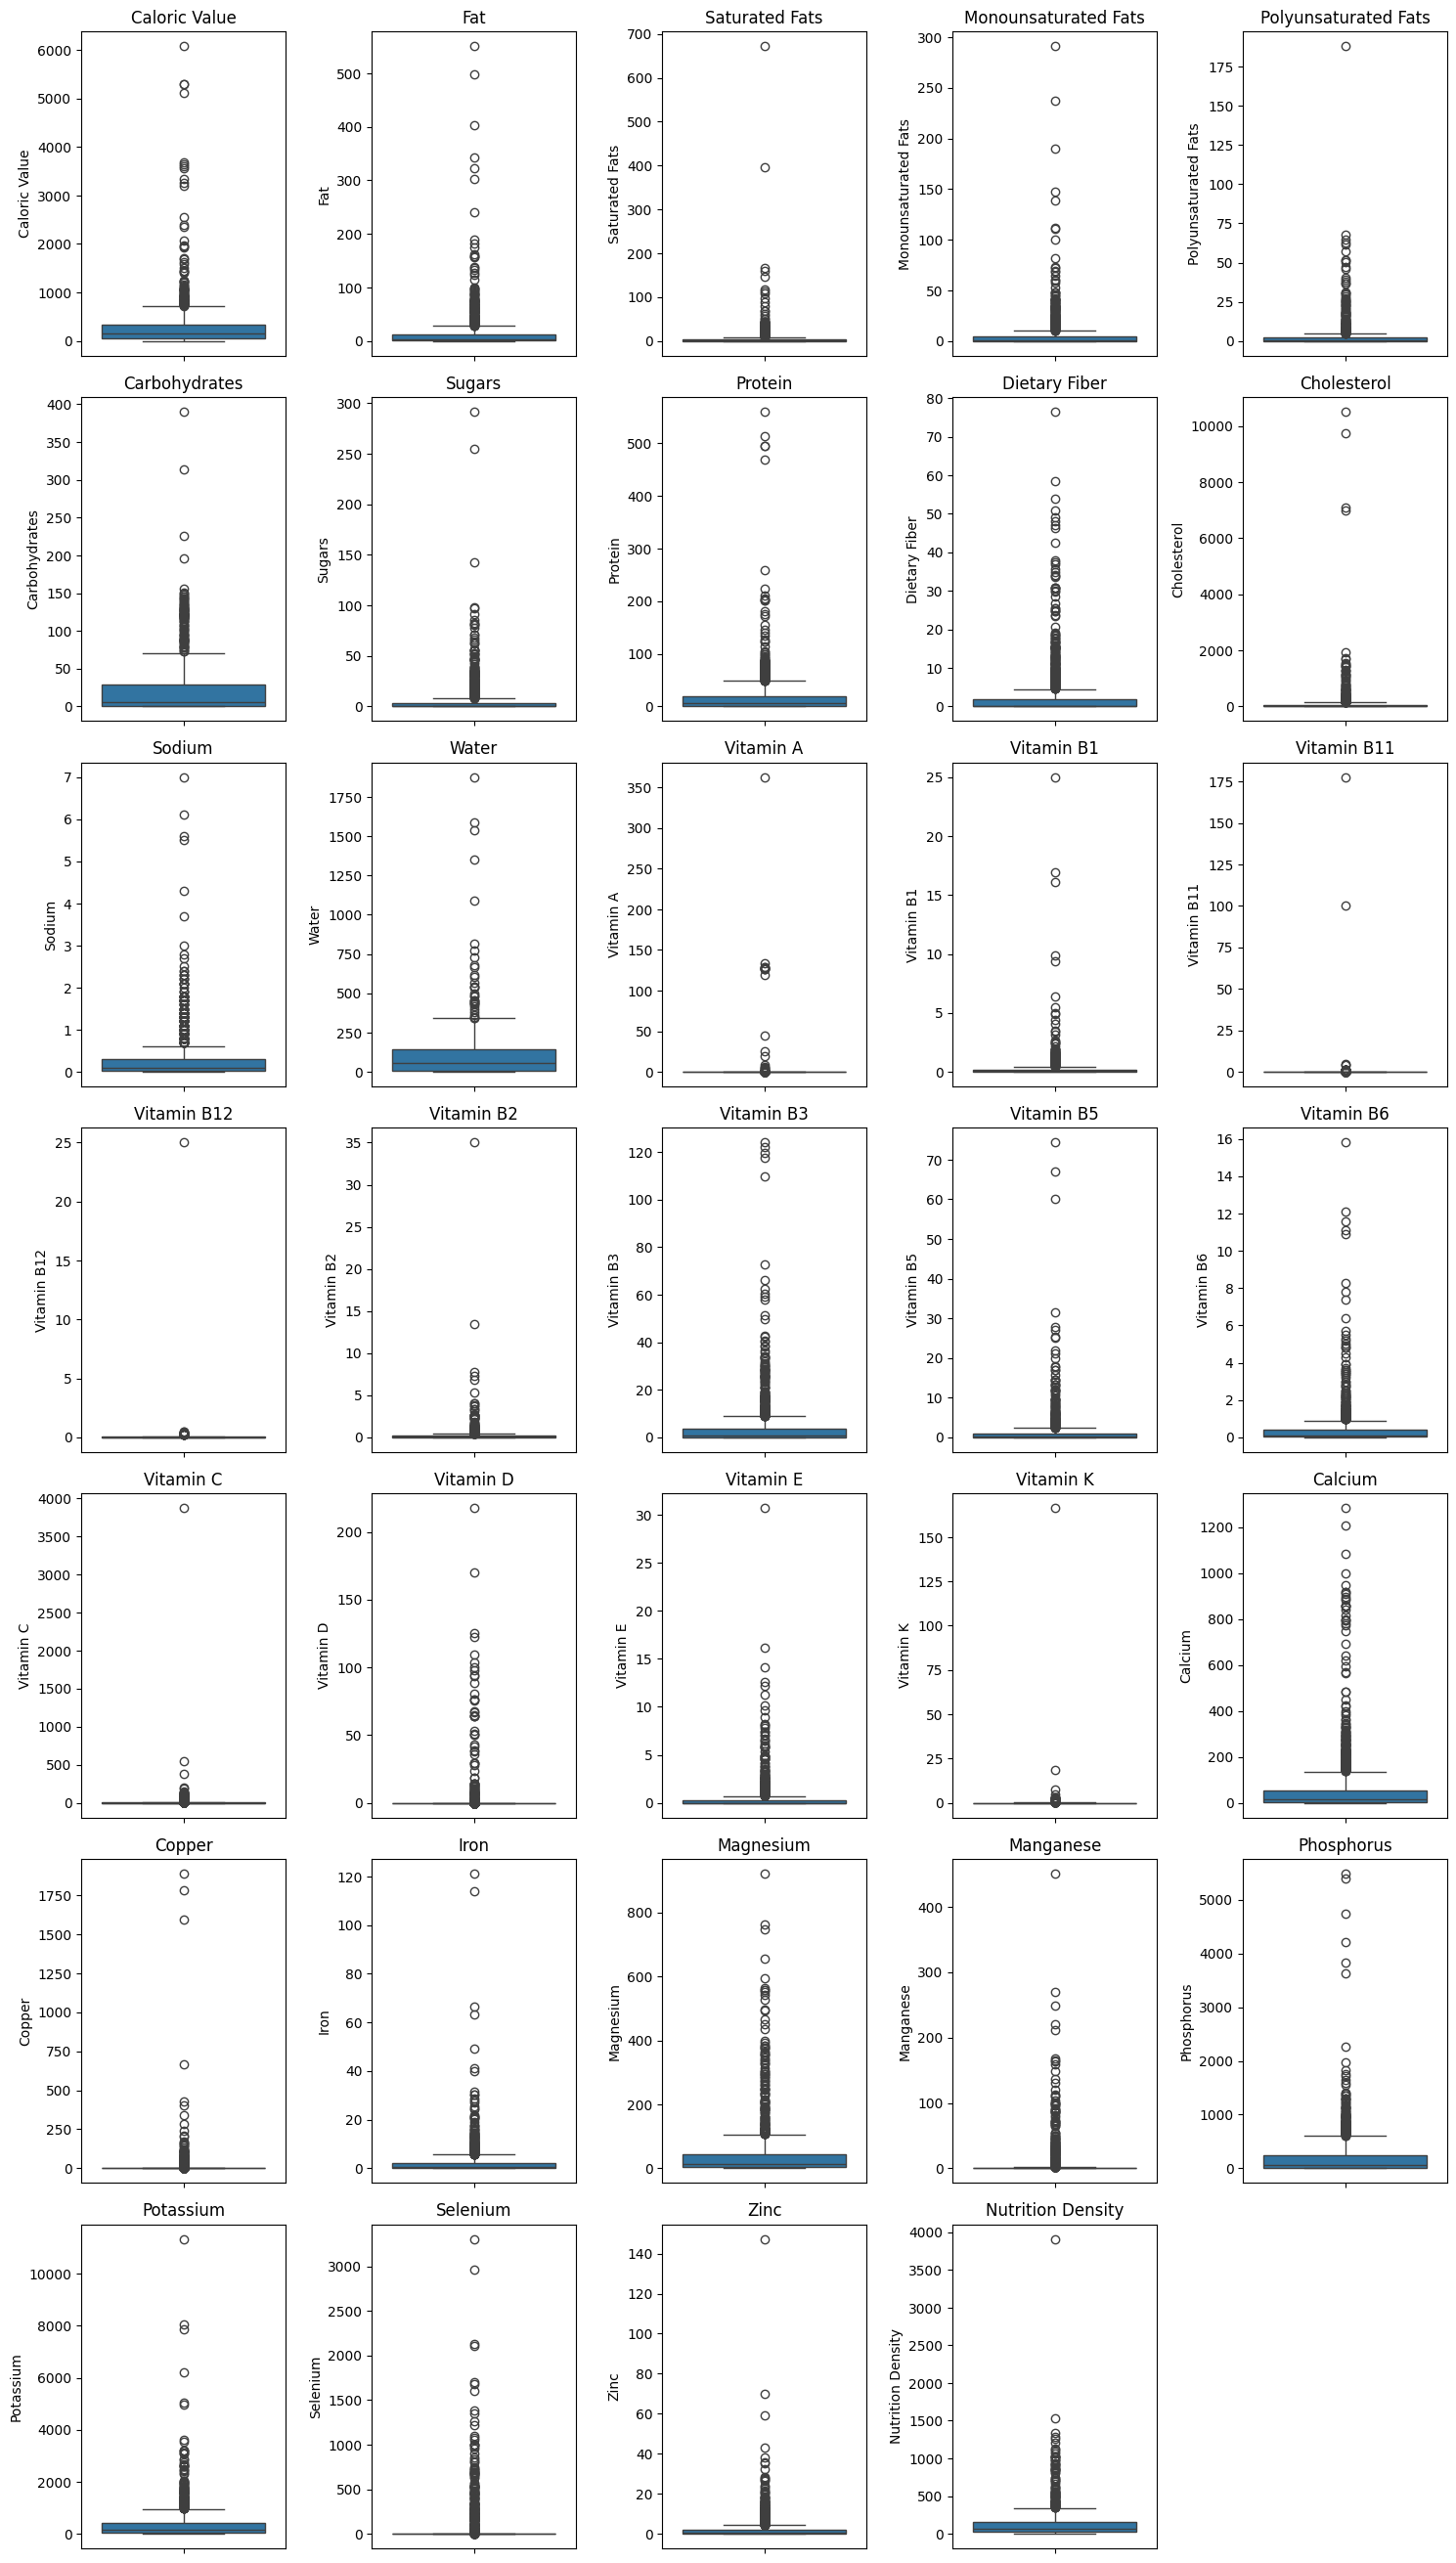

In [13]:
# @markdown посмотрим, как распределяются записи
columns_to_plot = df.columns.to_list()
columns_to_plot.remove("food")
plt.figure(figsize=(15, 30))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(8, 5, i)
    sns.boxplot(df[column])
    plt.title(column)
plt.tight_layout()
plt.show()

In [14]:
# @title
df[df["Fat"]>100]

,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,Protein,Dietary Fiber,...,Calcium,Copper,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density
707,banana cream pie,3190,161.3,44.6,67.8,39.0,390.2,143.0,52.2,8.3,...,889.5,0.600,12.3,189.8,1.800,1091.100,1956.9,0.100,5.7,1533.500
1009,coconut meat,1405,133.0,117.9,5.7,1.5,60.5,24.7,13.2,35.7,...,55.6,1.700,9.6,127.0,6.000,448.600,1413.3,0.056,4.4,320.700
1165,lamb sirloin raw,1234,100.3,44.1,41.2,7.8,0.0,0.0,76.8,0.0,...,45.4,0.500,7.3,99.8,0.024,721.200,1047.8,0.056,14.0,229.800
1169,lamb rib raw,1687,156.0,68.8,64.1,12.2,0.0,0.0,65.9,0.0,...,68.0,0.400,6.3,81.6,0.015,621.400,861.8,0.019,12.3,296.200
1185,ground beef raw,1506,136.1,51.2,59.7,3.2,0.0,0.0,65.1,0.0,...,108.9,0.200,7.4,63.5,0.045,598.800,988.8,0.001,16.2,317.500
1239,beef rib raw,1433,123.8,51.2,53.0,4.5,0.0,0.0,73.8,0.0,...,36.3,0.300,7.8,72.6,0.045,694.000,1179.4,0.067,17.0,241.700
1339,pork top loin roasts raw,3644,182.8,35.1,40.8,14.3,0.0,0.0,468.4,0.0,...,153.7,1.200,11.6,526.8,0.200,4741.200,7858.1,0.600,38.0,816.574
1341,pork backribs raw,2399,174.9,61.9,73.5,28.7,0.0,0.0,204.2,0.0,...,332.0,1.000,8.1,171.4,0.085,1649.300,2645.4,0.300,27.2,719.224
1357,pork carcass raw,1706,159.1,56.4,72.3,17.2,0.0,0.0,63.1,0.0,...,86.2,0.200,3.1,59.0,0.081,703.100,1147.6,0.100,7.2,313.327
1372,pork backfat,3683,402.3,146.1,190.3,46.9,0.0,0.0,13.2,0.0,...,9.1,0.094,0.8,9.1,0.082,172.400,294.8,0.063,1.7,425.932


Тут явно много выбросов. можно попробовать отбросить все записи, в которых масса нутриентов больше максимального значения. это частично спасет от выбросов

In [15]:
# @title
params = (  'Cholesterol','Protein', 'Sugars', 'Carbohydrates','Polyunsaturated Fats', 'Monounsaturated Fats', 'Saturated Fats', 'Fat','Water') #буквально выписал те, в которых максимальное значение >100

for param in params:
  df = df[df[param]<100]


In [16]:
# @title
df.shape

(898, 35)

In [17]:
#@markdown Создадим резервный датафрейм для сохранения  { display-mode: "form" }
df_SAVE = df.copy()

# [3.1] Независимая переменная №1

Возьмем в качестве первой независимой переменной жир,  т.к. его поведение предсказуемо

,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,Protein,Dietary Fiber,...,Calcium,Copper,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density





============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 879 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
879 non-null    float64
dtypes: float64(1)
memory usage: 13.7 KB
Количество:               879
Среднее:                  5.35
Минимум:                  0.0
Максимум:                 39.6
Стандартное отклонение:   6.97
25-й перцентиль:          0.3
50-й перцентиль:          2.5
75-й перцентиль:          8.25
95-й перцентиль:          19.8
25-й перцентиль и 50-й перцентили отстоят друг от друга на 05.6% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 14.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 29.2% от всей длины отрезка


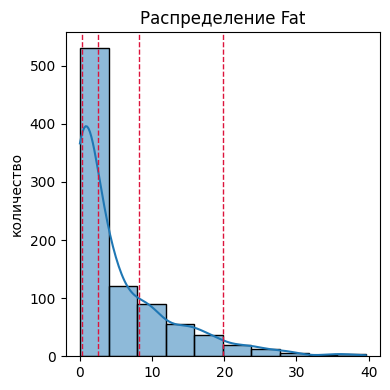

{'name': 'Fat',
 'amount': np.int64(879),
 'mean': np.float64(5.35),
 'min_value': 0.0,
 'max_value': 39.6,
 'std': 6.97,
 '25% quantile': np.float64(0.3),
 '50% quantile': np.float64(2.5),
 '75% quantile': np.float64(8.25),
 '95% quantile': np.float64(19.8)}

In [ ]:
# @markdown Быстрый анализ по жирам
EDA.EDA_one_param(df[df["Fat"]<40], "Fat")

In [ ]:
# @markdown проверка взаимозависимости величин
for i in df.columns.to_list()[1::]:
  print("\n"*3+
        "===="*15)
  print(f"check dependence of '{i}' and 'Fat'".center(75,"="))
  print(f"check linear dependence")
  print(check_undependence.check_R(df, "Fat",i))
  print(f"check mutual information dependence")
  check_undependence.checkMI(df, i,"Fat")





===============check dependence of 'Caloric Value' and 'Fat'===============
check linear dependence
0.7021
check mutual information dependence
MI = 0.52339 nats
p-value = 0.0000
NMI = 0.484



====================check dependence of 'Fat' and 'Fat'====================
check linear dependence
1.0
check mutual information dependence
MI = 1.08088 nats
p-value = 0.0000
NMI = 1.000



===============check dependence of 'Saturated Fats' and 'Fat'==============
check linear dependence
0.2331
check mutual information dependence
MI = 0.19612 nats
p-value = 0.0000
NMI = 0.388



============check dependence of 'Monounsaturated Fats' and 'Fat'===========
check linear dependence
0.4454
check mutual information dependence
MI = 0.27471 nats
p-value = 0.0000
NMI = 0.508



============check dependence of 'Polyunsaturated Fats' and 'Fat'===========
check linear dependence
0.6048
check mutual information dependence
MI = 0.22645 nats
p-value = 0.0000
NMI = 0.434



===============check dependence of 

Жиры зависят от (в порядке уменьшения связи)


1.   Своих производных ( ненасыщенные, насыщенные жиры ) (очевидно)
2.   Калорийность, причем **линейная** (очевидно)
3.   Витамины и минералы. больше всего натрий, магний, В1, Е, фосфор **(линейно)**, железо, кальций, плотность еды, белок **(линейно)**
4.   почти не зависит от всего остального


Первые две колонки очеивдны, интерес де факто представляет лишь третья колонка.
<br> натрий очевиден, ведь жирную еду часто солят (снэки,запеченные продукты, например)
<br> витамин Е жирорастворим, и запасается в нем. **ОДНАКО** остальные жирорастворимые витамины A,D,K мало коррелируют с жирами
<br> жир обладает молой плотностью по сравнению с другими макроэлементами, что в целом обьясняет взаимосвязь с плотностью еды (примечательно, что она нелинейна)
<br> Белок в целом также логичен, ведь жирами богата животная пища, которая также не менее богата белком (особенно кисломолочка и мясные продукты), однако линейность в данном случае обьяснить трудно.
<br>


In [ ]:
# @title
features = ['Caloric Value', 'Carbohydrates', 'Protein', 'Sugars','Fat']
duplicates = df[df.duplicated(subset=features, keep=False)]
display(duplicates.sort_values("Fat",ascending=True).head(5))

,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,Protein,Dietary Fiber,...,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density,Fat_min-max_std,Fat_mean-std
628,baking soda,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.0,0.000,0.0,0.0,0.018,0.000,0.000,0.0,-0.582272
1505,powerade zero ion4 coca cola,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.072,0.3,0.000,0.0,3.0,0.000,0.026,1.393,0.0,-0.582272
1047,salt,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.006,0.2,0.052,0.0,1.4,0.039,0.098,4.329,0.0,-0.582272
743,milk chocolate with rice cereal,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.0,0.000,0.0,0.0,0.000,0.000,0.000,0.0,-0.582272
1200,veal shoulder raw,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.0,0.000,0.0,0.0,0.000,0.000,0.000,0.0,-0.582272


Жиры не являются детерминированной функцией в контексте одного и того же блюда - ведь каждый раз ингридиенты будут немного разными( качественно, количественно по составу и количественно по отношению к другим ингридиентам в уже готовом блюде) и способ приготовления будет тоже немного отличаться.
<br> В контексте разных блюд мы тоже не можем сказать, что жиры - детерминированная величина. выше подобраны продукты с одинаковым составом макронутриентов и видно, что жиры у них **ОТЛИЧАЮТСЯ**.

In [ ]:
standartise.min_max_std(df,"Fat")
standartise.mean_std(df,"Fat")

Fat min-max standartised
new column = Fat_min-max_std
Fat mean standartised
new column = Fat_mean-std





====================== начинаем анализ по Fat_min-max_std ======================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Fat_min-max_std
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 14.0 KB
Количество:               898
Среднее:                  0.07
Минимум:                  0.0
Максимум:                 1.0
Стандартное отклонение:   0.12
25-й перцентиль:          0.0
50-й перцентиль:          0.03
75-й перцентиль:          0.09
95-й перцентиль:          0.25
25-й перцентиль и 50-й перцентили отстоят друг от друга на 03.0% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 06.0% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 16.0% от всей длины отрезка


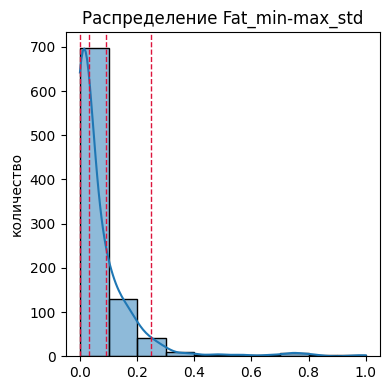

{'name': 'Fat_min-max_std',
 'amount': np.int64(898),
 'mean': np.float64(0.07),
 'min_value': 0.0,
 'max_value': 1.0,
 'std': 0.12,
 '25% quantile': np.float64(0.0),
 '50% quantile': np.float64(0.03),
 '75% quantile': np.float64(0.09),
 '95% quantile': np.float64(0.25)}

In [ ]:
# @title
EDA.EDA_one_param(df,'Fat_min-max_std')

25,50,75 перцентили стоят очень близко друг к другу, но не в упор, как в прошлом датасете. тут не похоже на дискретность, а скорее просто такое распределение. очень похоже на логнормальное. проверим это.

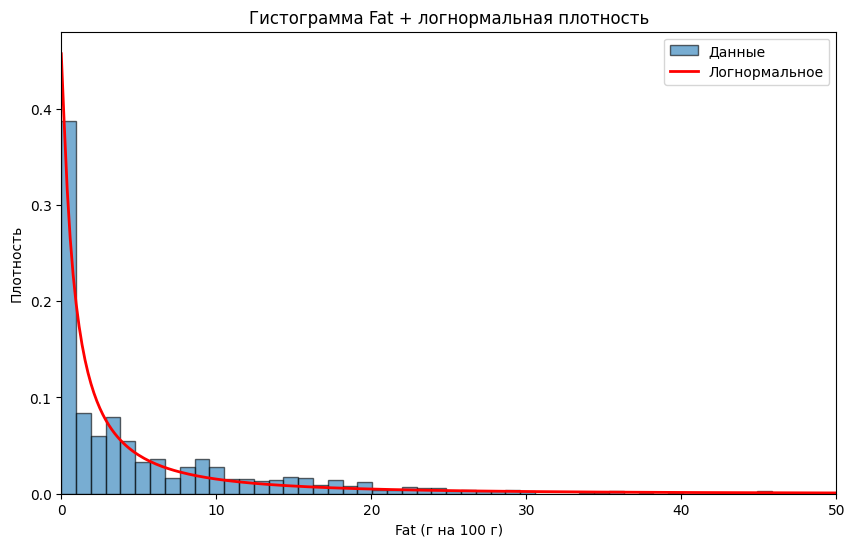

In [46]:
graphics.lognorm_graph(df,"Fat")

In [ ]:
# @title
df["Fat_mean-std"].describe()

,Fat_mean-std
count,8.980000e+02
mean,-7.912503e-18
std,1.000000e+00
min,-5.822722e-01
25%,-5.559946e-01
50%,-3.457737e-01
75%,1.885375e-01
max,7.782765e+00


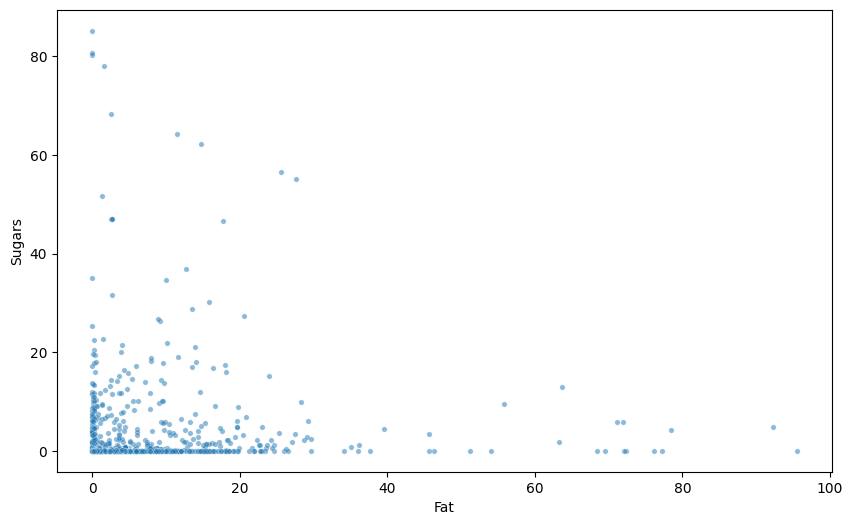

In [ ]:
# @markdown точечное распределение жира и любого параметра на выбор.
arg ="Sugars" # @param ['Caloric Value','Fat','Saturated Fats','Monounsaturated Fats','Polyunsaturated Fats','Carbohydrates','Sugars','Protein','Dietary Fiber','Cholesterol','Sodium','Water','Vitamin A','Vitamin B1','Vitamin B11','Vitamin B12','Vitamin B2','Vitamin B3','Vitamin B5','Vitamin B6','Vitamin C','Vitamin D','Vitamin E','Vitamin K','Calcium','Copper','Iron','Magnesium','Manganese','Phosphorus','Potassium','Selenium','Zinc','Nutrition Density']
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Fat",
                y=arg,
                alpha=0.5, s=15)
plt.show()

# [3.2] Независимая переменная №2

В качестве второй независимой переменной хочется взять плотность еды<sup>[1]</sup>. Т.к. подобные величины почти не измеряют, отчего представляет интерес с точки зрения изучения.
</br>проведем стандартный тест проверки зависимостей и попробуем обьяснить логическими рассуждениями


---

Примечания:
</br> [1] - плотность еды не в физическом смысле как количество массы на меру обьема. в нутрициологии плотность еды - количество "полезных" нутриентов на каллорию. (под "полезными" нутриентами понимают клетчатку, витамины, минералы). Плотность еды используется для составления рационов питания при похудении и восполнении дефицитов при минимальном каллораже еды.

In [ ]:
# @markdown взаимосвязь плотности еды  с другими показателями  { display-mode: "form" }
for i in df.columns.to_list()[1::]:
  print("\n"*3+
        "===="*15)
  print(f"check dependence of '{i}' and 'Nutrition Density'".center(75,"="))
  print(f"check mutual information dependence")
  check_undependence.checkMI(df, i,"Nutrition Density")




========check dependence of 'Caloric Value' and 'Nutrition Density'========
check mutual information dependence
MI = 0.28398 nats
p-value = 0.0000
NMI = 0.323



=============check dependence of 'Fat' and 'Nutrition Density'=============
check mutual information dependence
MI = 0.18221 nats
p-value = 0.0000
NMI = 0.208



========check dependence of 'Saturated Fats' and 'Nutrition Density'=======
check mutual information dependence
MI = 0.09433 nats
p-value = 0.0000
NMI = 0.187



=====check dependence of 'Monounsaturated Fats' and 'Nutrition Density'====
check mutual information dependence
MI = 0.06277 nats
p-value = 0.0000
NMI = 0.116



=====check dependence of 'Polyunsaturated Fats' and 'Nutrition Density'====
check mutual information dependence
MI = 0.07729 nats
p-value = 0.0000
NMI = 0.148



========check dependence of 'Carbohydrates' and 'Nutrition Density'========
check mutual information dependence
MI = 0.22015 nats
p-value = 0.0000
NMI = 0.251



============check depende

----

</br>Плотность еды показала следующие связи (в поредяке убывания):
</br>


1.   (Сильная): **Кальций (абсолютный лидер)**, Витамины Ц, А, калорийность
2.   (Заметная): Магний,Б1, железо,Фосфор,клетчатка, углеводы
3.   (Умеренная):  Жиры, белки, многие микроэлементы и минералы, вода
4.   (Почти отсутствует): сахар, почти все витаминны группы Б, Д,К, селен и медь.
</br></br> Попробуем описать полученные результаты с точки зрения логики


Кажется, это будет самая трудная переменная для обьяснения.
</br></br> Калций -  все очевидно - содержится в очень больших количествах в молочке ведь детенышам животных нужен дополнительный кальций для укрепления скелета ( как известно, кости многих животных(втч у людей) при рождении мягкие/обмягчены для уменьшения смертности при родах родителей и снижении риска переломов у детенышей ).
</br></br> Витамины Ц и А - в  больших количествах содержаться в соответствующих продуктах.
</br></br> по поводу **"заметной"** группы тоже в целом все понятно - зависимость будет примерно линейная скорее всего, ведь чем больше витаминов и клетчатки - тем выше плотность еды.  Углеводы имеют обратную сильную зависимость - они несут много энергии и не несут "полезной нагрузки" -> обратно пропорциональны
</br></br>в **умеренной** группе макронутриенты  будут увеличивать калорийность и не изменять количество "полезной нагрузки" следовательно, обратно пропорциональны плотности еды, но это в предельном случае. Но, вообще говоря, часто некоторым макронутриентам сопутствуют витамины или минералы - так, часть витаминов, как известно, жирорастворима - а значит, жир может порой наоборот, повышать ND(Nutrition Density), а с белком, как будет сказано далее, часто человек получает витаминны группы Б. Связь неоднозначна.

> *поэтому же в умеренную и почти отсутствующую группы попадает часть витаминов - они нередко сопутствуют каким-то калорийным вещетвам* и связь становится сильно запутанной

Положение воды тоже неоднозначно - ND это число "полезных" нутриентов на 1 калл. Не понятно, вода размывает больше каллории или минераллы с клетчаткой.

In [ ]:
# @markdown попробуем проверить ND и воду по Спирмену  {display-mode: "form" }
rho, p = spearmanr(df['Nutrition Density'], df['Water'])
print(f"Spearman: rho = {rho:.3f}, p = {p:.2e}")

Spearman: rho = 0.441, p = 5.17e-44


У нас умеренная положительная связь - т.е. вода размывает каллории больше, чем минералы, а значит плотность еды растет...
</br> вообще неочевидно, честно говоря. попробуем  линейную зависимость проверить
</br>Примечание: умеренная связь из за наличия других факторов, меняющих ND при том же количестве воды.

In [ ]:
# @markdown связь при этом явно нелинейная...  { display-mode: "form" }
print(f'Pearson R = {float(check_undependence.check_R(df,"Water", "Nutrition Density"))}')

Pearson R= 0.0589


минералы растворяются в воде, а жиры - нет. Возможно, большая часть витаминов и минералов просто водорастворима и с жиром уходит лишь небольшая часть "полезной" нагрузки но уходит много каллорий.
</br> попробуем взять записи выше медианы по воде и посмотреть на распределение ND там.

In [ ]:
df["Water"].quantile(0.5)

np.float64(12.25)




===================== начинаем анализ по Nutrition Density =====================
============================Nutrition Density ОБЩАЯ=============================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Nutrition Density
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 14.0 KB
Количество:               898
Среднее:                  75.79
Минимум:                  0.0
Максимум:                 1337.0
Стандартное отклонение:   135.74
25-й перцентиль:          11.07
50-й перцентиль:          32.78
75-й перцентиль:          84.69
95-й перцентиль:          267.5
25-й перцентиль и 50-й перцентили отстоят друг от друга на 01.6% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 03.9% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 13.7% от всей длины отрезка


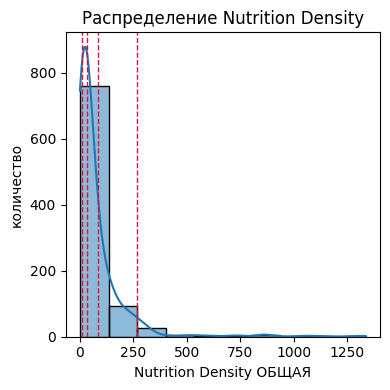




===================== начинаем анализ по Nutrition Density =====================
======================Nutrition Density вода выше квантиля======================

<class 'pandas.core.series.Series'>
Index: 449 entries, 1 to 1645
Series name: Nutrition Density
Non-Null Count  Dtype  
--------------  -----  
449 non-null    float64
dtypes: float64(1)
memory usage: 7.0 KB
Количество:               449
Среднее:                  100.22
Минимум:                  0.0
Максимум:                 1337.0
Стандартное отклонение:   164.38
25-й перцентиль:          20.22
50-й перцентиль:          51.2
75-й перцентиль:          109.1
95-й перцентиль:          313.57
25-й перцентиль и 50-й перцентили отстоят друг от друга на 02.3% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 04.3% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 15.3% от всей длины отрезка


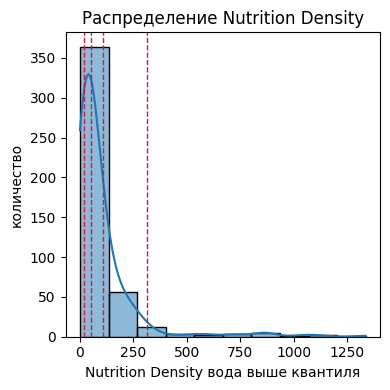

0.0

In [ ]:
before = EDA.EDA_one_param(df,"Nutrition Density",description="Nutrition Density ОБЩАЯ")
after = EDA.EDA_one_param(df[df["Water"]>12.25],"Nutrition Density",description="Nutrition Density вода выше квантиля")

In [ ]:
EDA.compare_EDAs(original = before,compared = after)


==================== сравнение EDA для 'Nutrition Density' =====================

Разница amount:          449.00(50.00%)      (исходное/новое):(898/449)
Разница mean:            -24.43(-32.23%)     (исходное/новое):(75.79/100.22)
Разница max_value:       0.00(0.00%)         (исходное/новое):(1337.0/1337.0)
Разница std:             -28.64(-21.10%)     (исходное/новое):(135.74/164.38)
Разница 25% quantile:    -9.15(-82.66%)      (исходное/новое):(11.07/20.22)
Разница 50% quantile:    -18.42(-56.19%)     (исходное/новое):(32.78/51.2)
Разница 75% quantile:    -24.41(-28.82%)     (исходное/новое):(84.69/109.1)
Разница 95% quantile:    -46.07(-17.22%)     (исходное/новое):(267.5/313.57)


Спирмен буквально работает на практике: увеличели воду и по всем показателям по которым могло увеличится, ND увеличилось... хорошо, теперь попробуем проверить поведение жира при повышенном количестве воды




============================ начинаем анализ по Fat ============================
===================================Fat ОБЩАЯ====================================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 14.0 KB
Количество:               898
Среднее:                  6.65
Минимум:                  0.0
Максимум:                 95.5
Стандартное отклонение:   11.42
25-й перцентиль:          0.3
50-й перцентиль:          2.7
75-й перцентиль:          8.8
95-й перцентиль:          23.62
25-й перцентиль и 50-й перцентили отстоят друг от друга на 02.5% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 06.4% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 15.5% от всей длины отрезка


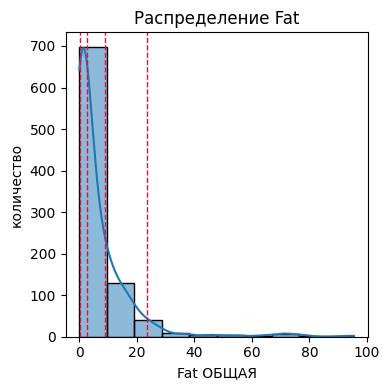




============================ начинаем анализ по Fat ============================
=============================Fat вода выше квантиля=============================

<class 'pandas.core.series.Series'>
Index: 449 entries, 1 to 1645
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
449 non-null    float64
dtypes: float64(1)
memory usage: 7.0 KB
Количество:               449
Среднее:                  7.37
Минимум:                  0.0
Максимум:                 63.7
Стандартное отклонение:   8.44
25-й перцентиль:          0.9
50-й перцентиль:          4.5
75-й перцентиль:          11.2
95-й перцентиль:          23.84
25-й перцентиль и 50-й перцентили отстоят друг от друга на 05.7% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 10.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 19.8% от всей длины отрезка


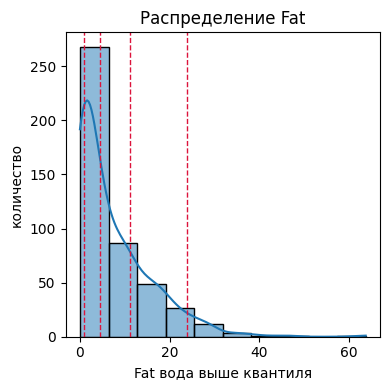


=========================== сравнение EDA для 'Fat' ============================

Разница amount:          449.00(50.00%)      (исходное/новое):(898/449)
Разница mean:            -0.72(-10.83%)      (исходное/новое):(6.65/7.37)
Разница max_value:       31.80(33.30%)       (исходное/новое):(95.5/63.7)
Разница std:             2.98(26.09%)        (исходное/новое):(11.42/8.44)
Разница 25% quantile:    -0.60(-200.00%)     (исходное/новое):(0.3/0.9)
Разница 50% quantile:    -1.80(-66.67%)      (исходное/новое):(2.7/4.5)
Разница 75% quantile:    -2.40(-27.27%)      (исходное/новое):(8.8/11.2)
Разница 95% quantile:    -0.22(-0.93%)       (исходное/новое):(23.62/23.84)


In [ ]:
before = EDA.EDA_one_param(df,"Fat",description="Fat ОБЩАЯ")
after = EDA.EDA_one_param(df[df["Water"]>12.25],"Fat",description="Fat вода выше квантиля")
before.pop("min_value")
after.pop("min_value")
EDA.compare_EDAs(original = before,compared = after)

Жир тоже подрос в значениях, что тоже логично, ведь жир используется как средство запасания воды (вспомним верблюдов, например)

Эта тема требует дальнейшего изучения и далее в рамках данной работы рассматриваться не будет.

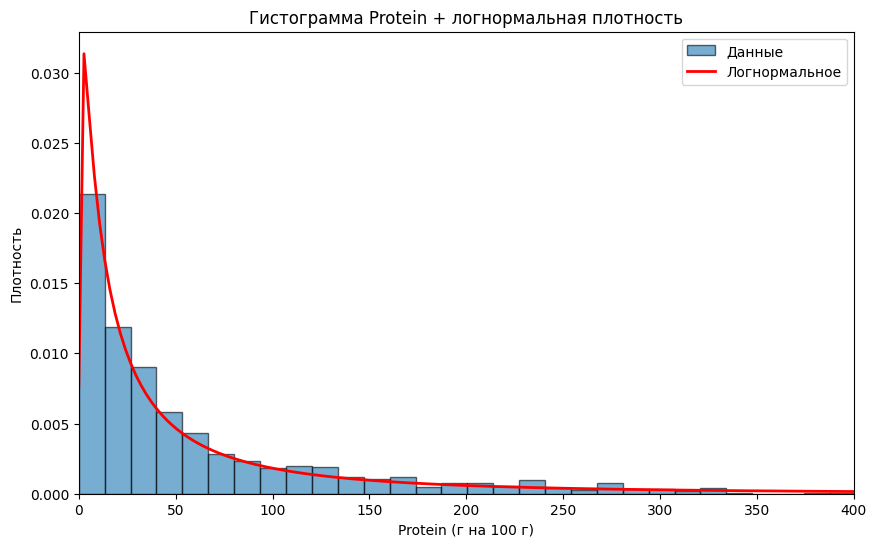

In [ ]:
# @markdown аппроксимируем логнормально  { display-mode: "form" }
x = df['Nutrition Density'].dropna().values
shape, loc, scale = stats.lognorm.fit(x, floc=-0.15)

# График
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(x, bins=100, density=True, alpha=0.6, edgecolor='black', label='Данные')

# Теоретическая кривая
xs = np.linspace(0, x.max(), 500)
ax.plot(xs, stats.lognorm.pdf(xs, shape, loc, scale), 'r-', linewidth=2, label='Логнормальное')

ax.set_xlim(0, 400) # Ограничим ось X, чтобы рассмотреть пик у нуля
ax.set_xlabel('Protein (г на 100 г)')
ax.set_ylabel('Плотность')
ax.set_title('Гистограмма Protein + логнормальная плотность')
ax.legend()
plt.show()

# [3.3] Независимая переменная №3

В качестве третьей независимой переменной хочется взять белок, т.к. он является важнейшим макронутриентом и хотелось бы изучить взаимосвязи белка с другими нутриентами.

In [ ]:
# @markdown взгляем на взаимосвязь белка с другими показателями  { display-mode: "form" }
for i in df.columns.to_list()[1::]:
  print("\n"*3+
        "===="*15)
  print(f"check dependence of '{i}' and 'Protein'".center(75,"="))
  print(f"check mutual information dependence")
  check_undependence.checkMI(df, i,"Protein")




=============check dependence of 'Caloric Value' and 'Protein'=============
check mutual information dependence
MI = 0.31501 nats
p-value = 0.0000
NMI = 0.219



==================check dependence of 'Fat' and 'Protein'==================
check mutual information dependence
MI = 0.19180 nats
p-value = 0.0000
NMI = 0.177



=============check dependence of 'Saturated Fats' and 'Protein'============
check mutual information dependence
MI = 0.06864 nats
p-value = 0.0000
NMI = 0.136



==========check dependence of 'Monounsaturated Fats' and 'Protein'=========
check mutual information dependence
MI = 0.08202 nats
p-value = 0.0000
NMI = 0.152



==========check dependence of 'Polyunsaturated Fats' and 'Protein'=========
check mutual information dependence
MI = 0.10116 nats
p-value = 0.0000
NMI = 0.194



=============check dependence of 'Carbohydrates' and 'Protein'=============
check mutual information dependence
MI = 0.13286 nats
p-value = 0.0000
NMI = 0.093



=================check de

----
связь белка с другими показателями оказалась скорее ожидаемой, чем наоборот.
</br>Белок показал следующие связи (в поредяке убывания):
</br>


1.   (Сильная): Фосфор, Витамин Б3, Калий, Витамин Б1
2.   (Заметная): Магний,Медь, Цинк, Б6, железо
3.   (Умеренная):  холестерол, Б5, вода, натрий, кальций, плотность еды
4.   (Слабая): все остальное, за исключением тех, у кого p>0.05 - они **не значимы**
</br></br> Попробуем описать полученные результаты с точки зрения логики


---
Фосфор: содержится в белках. После создания белка из аминокислот, к нему добавляется остаток **ФОСФОРНОЙ** кислоты, с помощью которой клетка осуществляет  контроль над активностью белков.
</br></br> также содержится в АТФ (Аденин Три ФОСФАТАХ), которые также содержаться в бОльшем количестве в мышцах(являются переносчиками почти чистой энергии - важно для мышц)

----
Витамины группы Б: всегда следуют с белками, являются обязательным условием метаболизма белка в организме.
</br></br>Примечание: некоторые витамины (Б5,например) показывают умеренную взаимосвязь. Так происходит, когда продукт изначально имел и белок и витамины, но вследствие приготовления потерял витаминную часть.
</br>Пример: некоторые кисломолочные продукты.

---
Калий: участвует в проведении сигнала между нервными клетками. Мясо за счет нейро-мышечной связи и для обеспечения контроля мозга над мышцами имеет повышенное содержание нервных клеток -> больше калия.
</br>также калий - клеточный катион, используемые втч для выработки энергии </br>(в целом значит, что также должен следователь вместе с АТФ (см выше про фосфор)) и для процессов метаболизма требуется с повышенных количествах

---
Магний: тоже очень важный микроэлемент. Участвует в метаболизме АТФ (см выше), также является кофактором многих ферментов, втч катаболических (сжигание энергии и создание новых веществ - рост мышц, например). в мышцах повышенное содержание катаболических центров, т.к. мышцы в процессе работы немного повреждаются (боль после занятий спортом)


----
Цинк - почти то же самое, что и магний, но он уже не столько активирует, сколько входит в состав некоторых ферментов.

---
железо - важнейший микроэлемент для дыхания - осуществляет перенос и метаболизм кислорода. Т.к. в мышцах тратится много энергии, нужно больше кислорода, чтобы сжигать энергию эффективнее -> нужно больше железа.

---
---
принцип доказательства независимости белка полонстью аналогичен жиру и здесь для краткости не приводится




========================== начинаем анализ по Protein ==========================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Protein
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 14.0 KB
Количество:               898
Среднее:                  6.59
Минимум:                  0.0
Максимум:                 65.1
Стандартное отклонение:   8.81
25-й перцентиль:          0.5
50-й перцентиль:          3.25
75-й перцентиль:          8.78
95-й перцентиль:          24.36
25-й перцентиль и 50-й перцентили отстоят друг от друга на 04.2% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 08.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 23.9% от всей длины отрезка


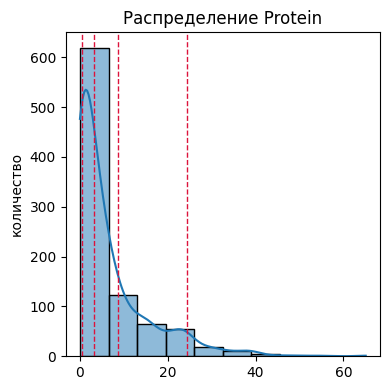

{'name': 'Protein',
 'amount': np.int64(898),
 'mean': np.float64(6.59),
 'min_value': 0.0,
 'max_value': 65.1,
 'std': 8.81,
 '25% quantile': np.float64(0.5),
 '50% quantile': np.float64(3.25),
 '75% quantile': np.float64(8.78),
 '95% quantile': np.float64(24.36)}

In [ ]:
EDA.EDA_one_param(df,"Protein")

In [ ]:
df.nlargest(3, "Protein")

,food,Caloric Value,Fat,Saturated Fats,Monounsaturated Fats,Polyunsaturated Fats,Carbohydrates,Sugars,Protein,Dietary Fiber,...,Calcium,Copper,Iron,Magnesium,Manganese,Phosphorus,Potassium,Selenium,Zinc,Nutrition Density
1641,lupins raw,668,17.5,2.1,7.1,4.4,72.7,0.0,65.1,34.0,...,316.8,1.8,7.8,356.4,4.3,792.0,1823.4,0.090,8.6,522.5
1131,winged beans raw,744,29.7,4.2,10.9,7.9,75.9,0.0,54.0,47.1,...,800.8,5.2,24.5,325.8,6.8,820.8,1778.1,0.058,8.2,1032.0
774,cottonseed kernels roasted,754,54.1,14.5,10.3,26.9,32.6,0.0,48.6,8.2,...,149.0,1.8,8.0,655.6,3.2,1192.0,2011.5,0.000,8.9,313.9


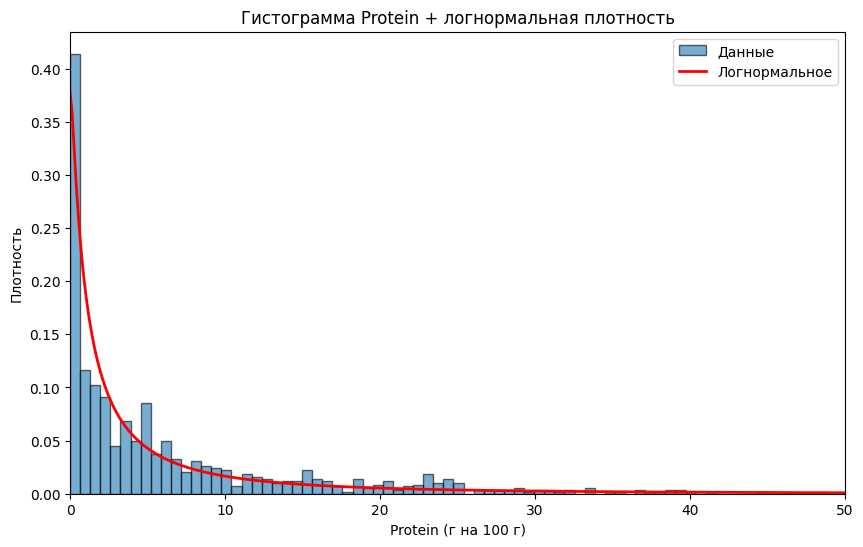

In [18]:
graphics.lognorm_graph(df,"Protein")

Буквально те же параметры, как и у жира, логнормального распределения и аппроксимирует неплохо. проверим на других параметрах. может быть, тут все величины имеют логнормальное распределение...

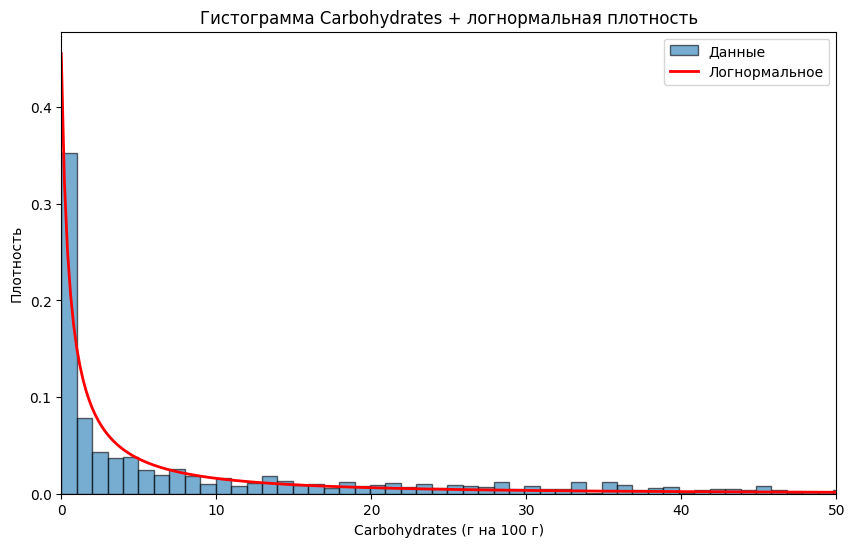

In [19]:
# @title
# @markdown точечное распределение жира и любого параметра на выбор.
arg ="Carbohydrates" # @param ['Caloric Value','Fat','Saturated Fats','Monounsaturated Fats','Polyunsaturated Fats','Carbohydrates','Sugars','Protein','Dietary Fiber','Cholesterol','Sodium','Water','Vitamin A','Vitamin B1','Vitamin B11','Vitamin B12','Vitamin B2','Vitamin B3','Vitamin B5','Vitamin B6','Vitamin C','Vitamin D','Vitamin E','Vitamin K','Calcium','Copper','Iron','Magnesium','Manganese','Phosphorus','Potassium','Selenium','Zinc','Nutrition Density']
graphics.lognorm_graph(df,arg)

многие параметры вцелом неплохо определяются, но логнормальное **не подходит**  многих витаминов

СФОРМУЛИРУЕМ ГИПОТЕЗУ

# [4] Гипотеза
</br> **все макронутриенты подчиняются логнормальному распределению**

In [22]:
#@markdown выпишем сначала все столбцы с данными и возьмем из них те, что относятся к макронутриентам  { display-mode: "form" }
print("  ".join(df.columns.to_list()[1::]))

Caloric Value  Fat  Saturated Fats  Monounsaturated Fats  Polyunsaturated Fats  Carbohydrates  Sugars  Protein  Dietary Fiber  Cholesterol  Sodium  Water  Vitamin A  Vitamin B1  Vitamin B11  Vitamin B12  Vitamin B2  Vitamin B3  Vitamin B5  Vitamin B6  Vitamin C  Vitamin D  Vitamin E  Vitamin K  Calcium  Copper  Iron  Magnesium  Manganese  Phosphorus  Potassium  Selenium  Zinc  Nutrition Density


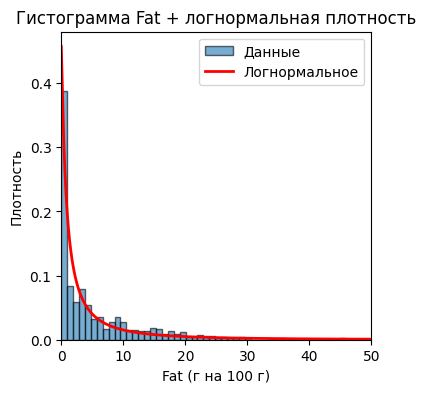

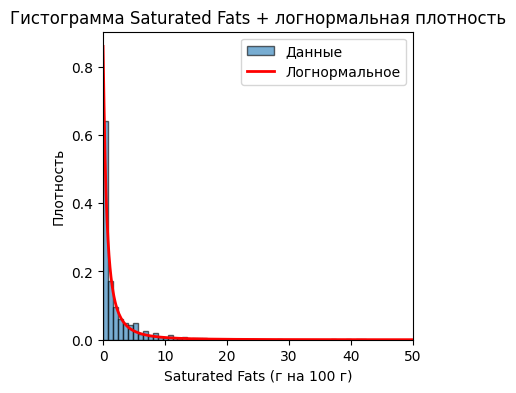

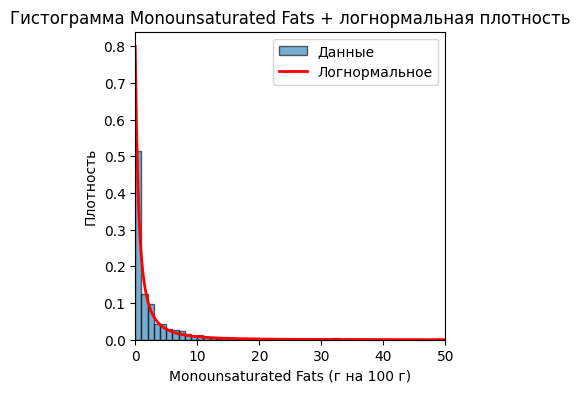

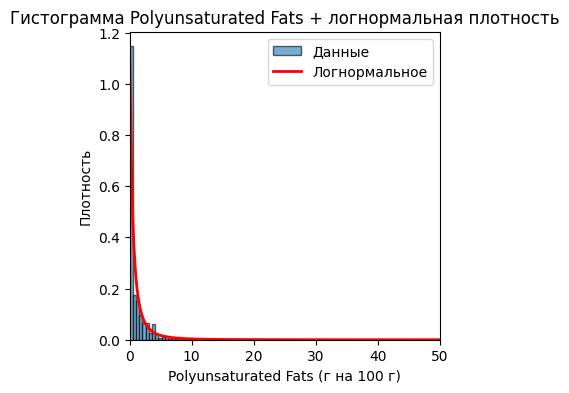

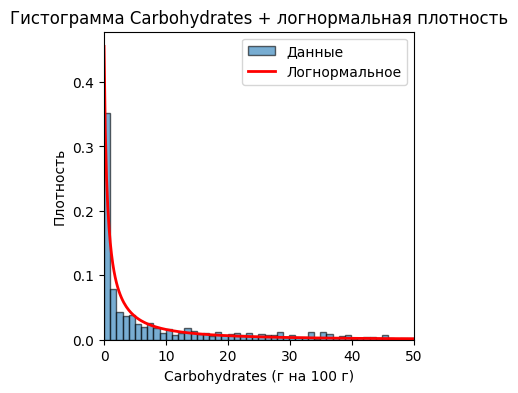

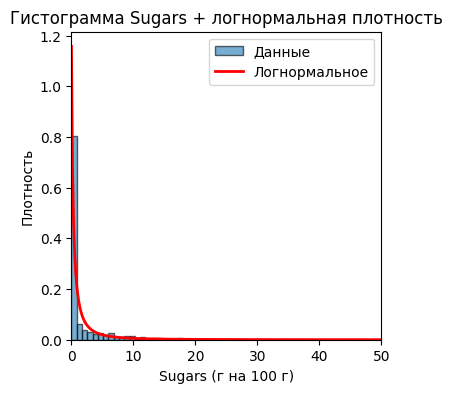

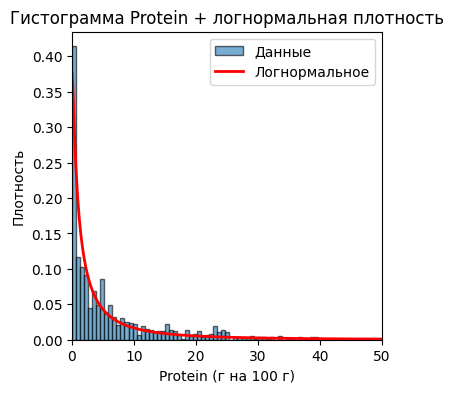

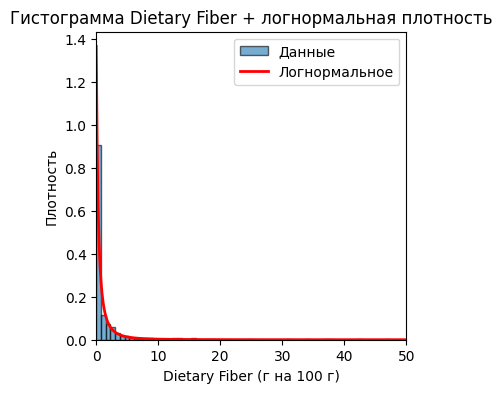

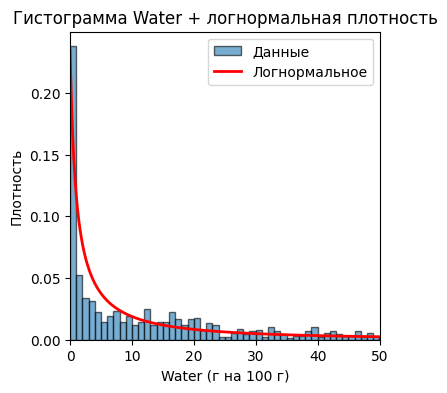

In [24]:

# @markdown построим графики всех макронутриентов и их близжайших производных
tupl = ('Fat','Saturated Fats','Monounsaturated Fats','Polyunsaturated Fats','Carbohydrates','Sugars','Protein','Dietary Fiber','Water')
for i in tupl:
    lognorm_graph(df,i, figsizz = (4,4))


Вывод: действительно, все макронутриенты могут быть аппроксимированны под логнормальное распределение. Исходя из информации из интернета, это обьясняется тем, что в биологии многое работает не на сложении, а на умножении. Таким образом, при умножении большого числа коэффициентов +- одного порядка, то итог будет концентрироваться таким образом, что если взять логарифм от полученного распределения, то получится нормальное распределение. попробуем получить это самое нормалььное распределение.


---
Примечание: в построении логнормальных распределений есть показатель floc - он отвечает за небольшое положительное смещение всех величин - это сделано специально для того чтобы была возможность учитывать те записи, величины которых по рассматриваемой составляющей были 0.


In [25]:
#@markdown Логарифм от нуля не определен. как поступить с нулями?  { display-mode: "form" }
x_pos = df['Fat'].dropna()
ans = "Заменить нули на Х" #@param ["Заменить нули на Х","Убрать значения, равные нулю "]
X = 0.1161 # @param {"type":"slider","min":0.0001,"max":2,"step":0.001}
if (ans[-1]=="Х"):
    x_pos = x_pos.replace(0, X)
else:
    x_pos = x_pos[x_pos > 0].values
#
#print(len(x_pos))


#print(len(x_pos))
x_log = np.log(x_pos)
df["ln(Fat)"] = x_log

Параметры нормального распределения для ln(X):
μ (среднее логарифмов) = 0.444
σ (стандартное отклонение) = 2.124


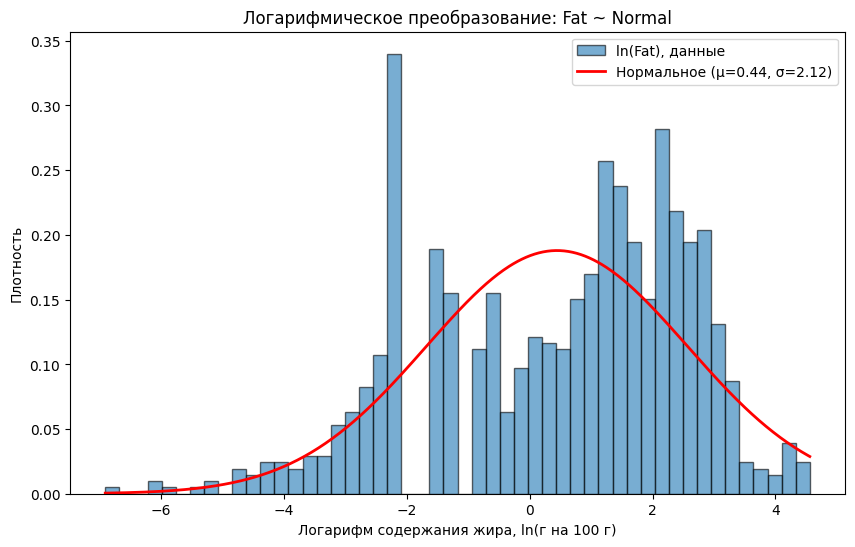

In [26]:
#@markdown строим распределение { display-mode: "form" }
mu, sigma = stats.norm.fit(x_log)
print(f"Параметры нормального распределения для ln(X):")
print(f"μ (среднее логарифмов) = {mu:.3f}")
print(f"σ (стандартное отклонение) = {sigma:.3f}")
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Гистограмма логарифмов (теперь она должна быть симметричной!)
ax.hist(x_log, bins=50, density=True, alpha=0.6, edgecolor='black', label='ln(Fat), данные')

# 2. Теоретическая кривая нормального распределения
xs = np.linspace(x_log.min(), x_log.max(), 500)
ax.plot(xs, stats.norm.pdf(xs, mu, sigma), 'r-', linewidth=2, label=f'Нормальное (μ={mu:.2f}, σ={sigma:.2f})')

# 3. Оформление
ax.set_xlabel('Логарифм содержания жира, ln(г на 100 г)')
ax.set_ylabel('Плотность')
ax.set_title('Логарифмическое преобразование: Fat ~ Normal')
ax.legend()
plt.show()

Примечание:  нулевые значения могут быть заменены на некоторые небольшие положительные значения - так мы учтем нули. За счет этого получается  высокий пик. В общем случае, конечно, часто к нулю приравнивают любые продукты, у которых количество жиров на 100 гр <0,5 гр.

</br> Заметим, что рспределение не нормальное, а похоже на смесь нормальных. проверим BIC

In [27]:
#@markdown BIC для числа компонентов  { display-mode: "form" }
res = math_model.bic_in_multinormal_model(df,"ln(Fat)")


components=1: BIC = 3914.67
components=2: BIC = 3768.08
components=3: BIC = 3791.38
components=4: BIC = 3816.63
components=5: BIC = 3829.47
components=6: BIC = 3821.42
components=7: BIC = 3826.15
components=8: BIC = 3825.13
components=9: BIC = 3844.77






=========== начинаем мультимодальный анализ для числа компонент = 2 ============

Средние компонент: [1.81, -1.84]
Дисперсии: [1.11, 1.88]
Веса: [0.63, 0.37]


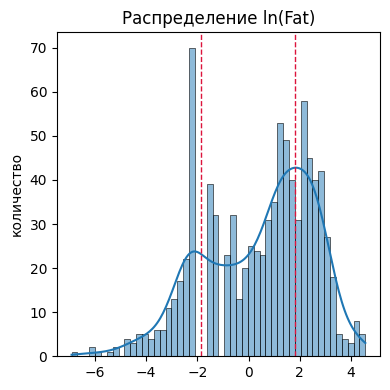

In [28]:
comp = "2" #@param [1,2,3,4,5,6,7,8,9]
math_model.check_multinormal_model(df,param = "ln(Fat)", components = int(comp),bins = 50)

Мы просто можем разбить все записи на низкожировые и высокожировые продукты (при двух компонентах) и в таком случае распределение выглядит хоть сколько нибудь вменяемым. однако мы должны помнить, что в датасете представленны и продукты,  и ингридиенты (а в данном случае разность критически важна )  ведь сливочное масло, например, имеет огромную жирность и не может употреблять в пищу индивидуально, никакую еду же так охарактеризовать нельзя.



---


# [5] Выборка


---

В данной главе будем пытаться сделать выборку из генеральной совокупности.

</br> Основная проблема такова:  за счет логнормального распределения шанс того, что наша выборка сильно съедет от изначальной, резко выше, т.к. значения сгрупированны около нуля и у нас есть очень длинный правый хвост.



общая стратегия реализации выборки такая: хочется оставить максимальные точки для удобной оценки корреляций. т.е. на начальных значениях ( где их большинство) мы можем построить аппроксимационную пряму, а потом посмотреть, насколько далеко отстоит от нее максимальный элемент. в связи с этим возникает проблема: у нас выборка автоматически не может быть маленькой, иначе экстремум будет сильно влиять на средние значения.
</br> Т.е. важно понять, что меня в данном случае интересует **точность** совпадения характеристик выборок, **а не компактность** полученной или скорость работы с ней.

In [21]:
# @markdown Возьмем основные макронутриенты, отбросив их производные. просто на основе предположения, что если макронутриент большой, то производные от него тоже будут увеличенны. Если в каждой категории брать, то  наша выборка по размерам максимум на пару десятков отличится от максимальной без уезжания значений, как мне кажется.
cols_to_max = ['Fat', 'Caloric Value', 'Carbohydrates', 'Protein', 'Sugars', 'Water'] # надпись отсюда переехала наверх)


extreme_indices = set()  # используем массив, чтобы избежать дубликатов - ведь одна запись может давать два экстремума. например - сливочное масло даст жир и калории скорее всего.
for col in cols_to_max:
    # idxmax() возвращает индекс строки с максимальным значением
    idx = df[col].idxmax()
    extreme_indices.add(idx)

extreme_indices = list(extreme_indices)
print(f"Найдено уникальных экстремумов: {len(extreme_indices)}")

Найдено уникальных экстремумов: 6
Индексы: [np.int64(1124), np.int64(1641), np.int64(619), np.int64(367), np.int64(1591), np.int64(670)]


Тут появилась проблема: мы должны стратифицировать и набрать подвыборку из... всей выборки! Что, вообще говоря, не просто. ведь разбить просто по квантилям одну какую то колонку и из нее набрать не все рвно, что учесть все интересующие нас колонки.
</br>
</br> Общая идея такая:


> У нас есть 6 колонок. Мы хотим выборку из Х. попробуем разбить каждую колонку на на все те же квантили и взять по выборке для каждой из колонки по Х/6. Возвращать обратно не будем. Потом попробуем собрать эти выборки обратно, и если какой-то клмпонент будет сьезжать, мы его доберем.


---

Примечание: помним, что скорость - не главное. мне важна точность с исходной. Поэтому Добирание до более близких значений не пугает. Меня лично устроит результат даже в уменьшении выборки на 20% при потери точности в не более чем 5%.



In [22]:
#@markdown инициализируем функцию для выборки (прошу прочитать комментарий вначале кода)  { display-mode: "form" }


#немного академ честности: дальше мне немного помогла нейронка, т.к. делается сия работа  в ночью (начиная с конца п. [4]). Беру на себя ответственность понимать строки кода, которые пишет нейронка при умении воспроизвести ход мыслей устно, но не гарантированно, что в коде при опросе "на месте".
# примечание: код нейронки все же будет редактироваться под нужды и логику задания, а не оставаться нетронутым.

import pandas as pd
import numpy as np

def make_sequential_stratified_sample(
    df: pd.DataFrame,
    cols: list, *,
    n_sample: int,
    n_strata: int = 5,
    random_state: int = 42
):
    rng = np.random.default_rng(random_state)

    # Создаем копию датафрейма-пула для вычерпывания
    pool = df.copy()

    # Списки для хранения индексов отобранных элементов
    sample_indices = []

    # =========================================================================
    # ЭТАП 1: Общий пул экстремумов (max по каждой колонке)
    # =========================================================================
    extreme_indices = set()
    for col in cols:
        idx = pool[col].idxmax()
        extreme_indices.add(idx)

    extreme_indices = list(extreme_indices)

    # Добавляем экстремумы в выборку и удаляем из пула
    sample_indices.extend(extreme_indices)
    pool = pool.drop(index=extreme_indices)

    # Сколько элементов осталось набрать
    n_remaining = n_sample - len(extreme_indices)
    n_per_col = n_remaining / len(cols)  # Доля на каждую колонку

    # =========================================================================
    # ЭТАП 2: Итеративный проход по колонкам
    # =========================================================================
    for col in cols:
        # 2.1. Сколько нужно взять для текущей колонки (округляем)
        n_take_target = max(1, round(n_per_col))

        # 2.2. Разбиваем ТЕКУЩИЙ пул на 5 квантилей по текущей колонке
        # rank(method='first') нужен, чтобы qcut не падал на одинаковых значениях (нули)
        strata = pd.qcut(
            pool[col].rank(method='first'),
            q=n_strata,
            labels=False,
            duplicates='drop'
        )

        # Считаем размеры страт в текущем пуле
        strata_sizes = strata.value_counts()
        total_pool_size = len(pool)

        picked_col_indices = []

        # 2.3. Пропорциональный отбор из каждой страты
        for stratum, size in strata_sizes.items():
            # Идеальное количество из страты (пропорционально её размеру)
            n_take_stratum = max(1, round(size / total_pool_size * n_take_target))

            # Не берем больше, чем есть в страте
            n_take_stratum = min(n_take_stratum, size)

            # Кандидаты в этой страте
            candidates = strata[strata == stratum].index.tolist()

            # Случайно выбираем нужное количество
            picked = rng.choice(candidates, size=n_take_stratum, replace=False).tolist()
            picked_col_indices.extend(picked)

            # Останавливаемся, если набрали достаточно для этой колонки
            if len(picked_col_indices) >= n_take_target:
                break

        # Обрезаем лишнее (если набрали чуть больше из-за max(1, ...))
        picked_col_indices = picked_col_indices[:n_take_target]

        # 2.4. Добавляем в выборку и удаляем из пула
        sample_indices.extend(picked_col_indices)
        pool = pool.drop(index=picked_col_indices)

        # Корректируем n_per_col для следующих итераций,
        # чтобы компенсировать округления (если взяли меньше/больше)
        n_remaining -= len(picked_col_indices)
        remaining_cols = len(cols) - cols.index(col) - 1
        if remaining_cols > 0:
            n_per_col = n_remaining / remaining_cols

    # =========================================================================
    # ЭТАП 3: Финальный буфер (добор до n_sample)
    # =========================================================================
    # Из-за округлений и обрезаний может не хватить пары элементов
    deficit = n_sample - len(sample_indices)
    if deficit > 0 and len(pool) > 0:
        extra_indices = rng.choice(pool.index.tolist(), size=min(deficit, len(pool)), replace=False).tolist()
        sample_indices.extend(extra_indices)
        pool = pool.drop(index=extra_indices)

    # Формируем итоговый датафрейм
    sample_df = df.loc[sample_indices].copy()

    # =========================================================================
    # ЭТАП 4: Контроль (сравнение средних и медиан)
    # =========================================================================
    print("=" * 60)
    print("КОНТРОЛЬ КАЧЕСТВА ВЫБОРКИ")
    print(f"Размер генеральной совокупности: {len(df)}")
    print(f"Размер выборки: {len(sample_df)}")
    print("=" * 60)

    control_data = []
    for col in cols:
        gen_mean = df[col].mean()
        smp_mean = sample_df[col].mean()

        gen_med = df[col].median()
        smp_med = sample_df[col].median()

        # Относительное отклонение среднего
        dev_mean = abs(smp_mean - gen_mean) / (abs(gen_mean) + 1e-9) * 100
        # Относительное отклонение медианы
        dev_med = abs(smp_med - gen_med) / (abs(gen_med) + 1e-9) * 100

        control_data.append({
            'Колонка': col,
            'Mean (ген)': gen_mean,
            'Mean (выб)': smp_mean,
            'Откл Mean %': dev_mean,
            'Median (ген)': gen_med,
            'Median (выб)': smp_med,
            'Откл Median %': dev_med
        })

    control_df = pd.DataFrame(control_data).set_index('Колонка')

    # Красивый вывод таблицы
    pd.set_option('display.float_format', lambda x: f'{x:.2f}')
    print(control_df)
    print("=" * 60)

    # Предупреждение, если какая-то колонка сильно съехала (например, > 15%)
    for col in cols:
        if control_df.loc[col, 'Откл Mean %'] > 15.0:
            print(f"⚠️ ВНИМАНИЕ: Колонка '{col}' съехала по среднему более чем на 15%!")

    return sample_df

# Пример вызова:
# cols_to_max = ['Fat', 'Caloric Value', 'Carbohydrates', 'Protein', 'Sugars', 'Water']
# sample = make_sequential_stratified_sample(df, cols_to_max, n_sample=300)

In [23]:
#@markdown размер выборки  { display-mode: "form" }
N = 440 # @param {"type":"slider","min":10,"max":850,"step":10}
sample = make_sequential_stratified_sample(df, cols_to_max, n_sample=N)

КОНТРОЛЬ КАЧЕСТВА ВЫБОРКИ
Размер генеральной совокупности: 898
Размер выборки: 440
               Mean (ген)  Mean (выб)  Откл Mean %  Median (ген)  \
Колонка                                                            
Fat                  6.65        6.95         4.48          2.70   
Caloric Value      142.32      148.23         4.15         94.00   
Carbohydrates       13.18       13.68         3.80          3.75   
Protein              6.59        6.92         4.97          3.25   
Sugars               3.22        3.21         0.58          0.00   
Water               23.34       23.99         2.78         12.25   

               Median (выб)  Откл Median %  
Колонка                                     
Fat                    2.35          12.96  
Caloric Value         97.00           3.19  
Carbohydrates          3.60           4.00  
Protein                3.10           4.62  
Sugars                 0.00           0.00  
Water                 12.55           2.45  


Возьмем +-50% = 440 записей. в целом скорее получилось, чем наоборот
</br></br>  средние съехали не более чем на 5%, что хорошо, а медианы у жира пляшут, но, вообще говоря, там погрешность менее 0,5 гр. т.е. тут не процентное отношение, а абсолютное позволяет сказать, что мы можем закрыть глаза и сказать, что в целом-то весьма репрезентативно!
</br> теперь проверим каждый "ключевой" параметр ДФ по отдельности

In [25]:
#@markdown EDA по основным нутриентам для всей совокупности и нашей выборки, а также их сравнение. нас интересует только сравнение по сути.   { display-mode: "form" }
shut_extra_info = True # @param {type:"boolean"}
df400 = df.copy()
df400[cols_to_max] = df400[cols_to_max].replace(0, 0.1)
sample[cols_to_max] = sample[cols_to_max].replace(0, 0.1)
for i in cols_to_max:
    First = EDA.EDA_one_param(sample,i,shut_graphics=shut_extra_info,shut_print=shut_extra_info)
    Second = EDA.EDA_one_param(df400,i,shut_graphics=shut_extra_info,shut_print=shut_extra_info)
    EDA.compare_EDAs(original = Second, compared=First)




============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 440 entries, 1124 to 273
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
440 non-null    float64
dtypes: float64(1)
memory usage: 6.9 KB



============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 46.3 KB

=========================== сравнение EDA для 'Fat' ============================

Разница amount:          -458.00(-51.00%    )(исходное/новое):(898/440)
Разница mean:            0.30(4.51%    )     (исходное/новое):(6.65/6.95)
Разница min_value:       0.00(/0(!!)    )    (исходное/новое):(0.0/0.0)
Разница max_value:       0.00(0.00%    )     (исходное/новое):(95.5/95.5)
Разница std:             1.38(12.09%    )    (исходное/новое):

у всех значений стандартное отклонение поехало и квантили. по итогу либо в абсолютных величинах разница смешная, либо в процентах небольшая, поэтому можно говорить, что по основным отобранным параметрам можно смело говорить об успешной выборке в менее чем 50% обьемом от исходной при достаточно хорошей точности!

In [27]:
#@markdown тут предлагается сравнить остальные параметры при наличии интереса  { display-mode: "form" }
i = "Fat" # @param ['Caloric Value','Fat','Saturated Fats','Monounsaturated Fats','Polyunsaturated Fats','Carbohydrates','Sugars','Protein','Dietary Fiber','Cholesterol','Sodium','Water','Vitamin A','Vitamin B1','Vitamin B11','Vitamin B12','Vitamin B2','Vitamin B3','Vitamin B5','Vitamin B6','Vitamin C','Vitamin D','Vitamin E','Vitamin K','Calcium','Copper','Iron','Magnesium','Manganese','Phosphorus','Potassium','Selenium','Zinc','Nutrition Density']
shut_extra_info = True # @param {type:"boolean"}
if not shut_extra_info: print("БЫЛО".center(80,"^"))
Second = EDA.EDA_one_param(df400,i,shut_graphics=shut_extra_info,shut_print=shut_extra_info)
if not shut_extra_info: print("\n"*4+"СТАЛО".center(80,"^"))
First = EDA.EDA_one_param(sample,i,shut_graphics=shut_extra_info,shut_print=shut_extra_info)
EDA.compare_EDAs(original = Second, compared=First)




============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 46.3 KB



============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 440 entries, 1124 to 273
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
440 non-null    float64
dtypes: float64(1)
memory usage: 6.9 KB

=========================== сравнение EDA для 'Fat' ============================

Разница amount:          -458.00(-51.00%    )(исходное/новое):(898/440)
Разница mean:            0.30(4.51%    )     (исходное/новое):(6.65/6.95)
Разница min_value:       0.00(/0(!!)    )    (исходное/новое):(0.0/0.0)
Разница max_value:       0.00(0.00%    )     (исходное/новое):(95.5/95.5)
Разница std:             1.38(12.09%    )    (исходное/новое):

# [6.1] Генератор случайных исел

[ССЫЛКА НА СТАТЬЮ](https://cyberleninka.ru/article/n/generator-sluchaynyh-chisel-raspredelennyh-po-lognormalnomu-zakonu)

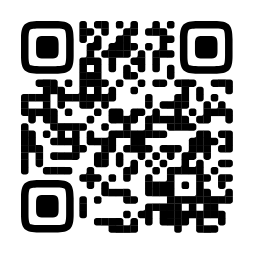

Немного теории из статьи: сия статья описывает силу сигнала WI-FI для "обеспечения соответствия уровня сигнала вне здания государственным нормам и контроля подключений к
сети вне периметра помещения".
<br> я так понял, что тут моделируется либо удаление качества сигнала с расстоянием ( из за того что мы живем в век технологий, то удаление от источника сигнала уменьшает сигнал не линейно, а по логнормальному распределению из за лютой интерференции и огромного числа других сигналов) <br><br>или мощности передатчика при неизменной мощности мобильного устройства ( исходя из моих знаний по системному администрированию, то если стационарный датчик на максимальной мощности, а мабильное устройство слабенькое, то за счет той же интерференции стационарное устройство просто будет перебивать сигнал от мобильного устройства, т.к. протоколы для  гарантированной доставки (TCP) требуют, чтобы мобильное устройство подтвердило получение пакета, и т.к. сие мобильное устройство слабенькое, то сигнал из за мощности стационарного не доходит и стационарка посылает вновь и вновь эти пакеты и мобильное устройство просто не "достукивается" до стационарки)

<br><br>

---



---

Общая идея алгоритма очень проста - поэтому, собственно, я его и выбрал, а состоит она в следующем: просто разбиваем весь отрезок на N бинов. в каждом из бинов смотрим плотность функции - буквально сколько записей попало поделить на всё число записей. Затем просто согласно полученным плотностям равномерно распихиваем в каждый из бинов нужное  количество записей. ВСЁ!
<br> простота, конечно плохо влияет на точность, но скорость алгоритма должна быть высокой: ведь мы просто проходим по каждой из записей и добавляем единичку в  счетчик для соответствующего отрезка. дальше просто поделить и рассыпать нужное число записей. каждая запись генерируется очень быстро - ведь это дефакто "стандартная" генерация компьютера от 0 до 1 и последующее умножение - делается очень быстро и растет линейно с числом записей. изначальный подсчет тоже должен быть быстрым - растет линейно с числом записей в датафрейме и с числом бинов. бинов сильно меньше числа записей, поэтому просто скорость порядка записей в датафрейме должна быть. ну на крайняк x<sup>2</sup>

In [29]:
#@markdown Восстановиться с сохраненного датафрейма (нужно восстанавливаться каждый раз при смене значений в окне выбора для исходного датафрейма)  { display-mode: "form" }
df = df_SAVE.copy()

In [30]:
#@markdown пропишем генератор в соответствии со статьей  { display-mode: "form" }
def p_small(x, m, sigma):
    return (1 / (sigma * x * np.sqrt(2 * np.pi))) * np.exp(
        -((np.log(x) - m) ** 2) / (2 * sigma ** 2)
    )

def generate_new_lines(
    df_big: pd.DataFrame,
    column: str, *,
    amount: int = 1000,
    bins:int = 30
):
    df = df_big[column]
    mu = np.log(df).mean()
    sigma = np.log(df).std(ddof=0)
    a = min(df)
    b = max(df)
    edges   = np.linspace(a, b, bins + 1)
    centers = (edges[1:] + edges[:-1]) / 2

    p_i = p_small(centers, mu, sigma)      # массив длиной k
    weights = p_i / p_i.sum()
    n_i_float = weights * amount
    n_i = np.floor(n_i_float).astype(int)

    # добить остаток до ровно n (в подынтервалы с наибольшим дробным остатком)
    rem = amount - n_i.sum()
    if rem > 0:
        frac  = n_i_float - n_i
        order = np.argsort(frac)[::-1]
        n_i[order[:rem]] += 1

    rng = np.random.default_rng(42)
    parts = []
    for i in range(bins):
      if n_i[i] > 0:
         parts.append(rng.uniform(edges[i], edges[i + 1], n_i[i]))

    sample = np.concatenate(parts)
    rng.shuffle(sample)                 # перемешать
    print(column)
    return pd.DataFrame({column: sample})


In [31]:
#@markdown Логарифм от нуля не определен. как поступить с нулями?  { display-mode: "form" }
dfF = df.copy()
ans = "Убрать значения, равные нулю " #@param ["Заменить нули на Х","Убрать значения, равные нулю "]
X = 0.0001 # @param {"type":"slider","min":0.0001,"max":1,"step":0.001}
if (ans[-1]=="Х"):
    dfF['Fat'] = df['Fat'].replace(0, X)
else:
    dfF = df[df['Fat'] > 0]

In [32]:
#@markdown как поступить с нулями в исходном датафрейме для сравнения?  { display-mode: "form" }
df = df_SAVE.copy()
ans = "Оставить, как есть" #@param ["Заменить нули на Х","Убрать значения, равные нулю ", "Оставить, как есть"]
X = 0.0001 # @param {"type":"slider","min":0.0001,"max":1,"step":0.001}
if (ans[-1]=="Х"):
    df['Fat'] = df['Fat'].replace(0, X)
elif ans[0]=="У":
    df = df[df['Fat'] > 0]
else:
    pass

In [33]:
#@markdown сгенерируем выборку  { display-mode: "form" }
Bins = 100 # @param {type:"number"}
Amount = 800 # @param {type:"number"}
dfF = generate_new_lines(dfF, "Fat", amount = Amount,bins= Bins)

Fat


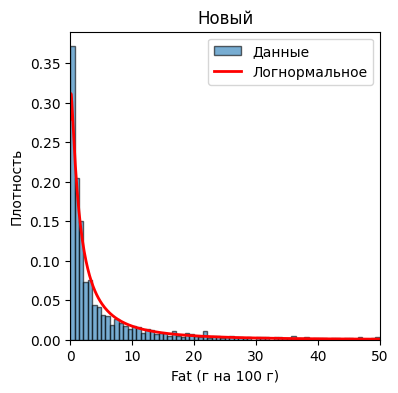

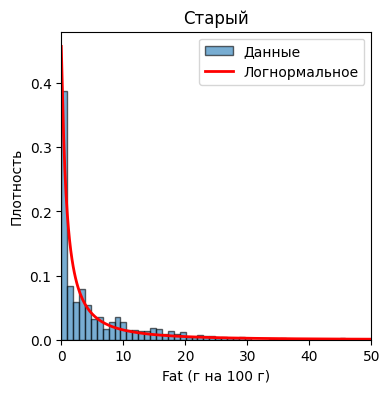

In [37]:
#@markdown посмотрим аппроксимацию новой и старой  { display-mode: "form" }
graphics.lognorm_graph(dfF,"Fat", figsizz = (4,4),description = "Новый")
graphics.lognorm_graph(df,"Fat", figsizz = (4,4),description = "Старый")

In [38]:
#@markdown пробежимся быстрым анализом и сравним их  { display-mode: "form" }
shut_extra_info = True
EDA.compare_EDAs(original = EDA.EDA_one_param(df,"Fat",description = "Старый",shut_graphics=shut_extra_info,shut_print=shut_extra_info),compared = EDA.EDA_one_param(dfF,"Fat",description = "Новый",shut_graphics=shut_extra_info,shut_print=shut_extra_info))




============================ начинаем анализ по Fat ============================
=====================================Старый=====================================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 46.3 KB



============================ начинаем анализ по Fat ============================
=====================================Новый======================================

<class 'pandas.core.series.Series'>
RangeIndex: 800 entries, 0 to 799
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
800 non-null    float64
dtypes: float64(1)
memory usage: 6.4 KB

=========================== сравнение EDA для 'Fat' ============================

Разница amount:          -98.00(-10.91%    ) (исходное/новое):(898/800)
Разница mean:            0.60(9.02%    )     (исходное/новое):(6.65/7.25)
Разница min_value:       0.01(/0(!!)    )   

При числе бинов в генерации = 50 (иксы удержали при 0,0001), у нас сьезжает среднее на 1.43, среднее отклонение и 95 квантиль(этот очень сильно) . можно попробовать обрезать по 95 квантилю изначальной выборки и попробовать сравнить вновь.
<br> при 100 бинах отклоняются также только квантили. с ростом числа сгенерированных записей заметных эффектов не удается достичь.

In [39]:
#@markdown обрезали по 95 квантилю две выборки. смотрим на данные:  { display-mode: "form" }
EDA.compare_EDAs(original = EDA.EDA_one_param(df[df['Fat']<35.7],"Fat",shut_graphics=shut_extra_info,shut_print=shut_extra_info),compared = EDA.EDA_one_param(dfF[dfF['Fat']<35.7],"Fat",shut_graphics=shut_extra_info,shut_print=shut_extra_info))




============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 875 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
875 non-null    float64
dtypes: float64(1)
memory usage: 13.7 KB



============================ начинаем анализ по Fat ============================

<class 'pandas.core.series.Series'>
Index: 759 entries, 0 to 799
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
759 non-null    float64
dtypes: float64(1)
memory usage: 11.9 KB

=========================== сравнение EDA для 'Fat' ============================

Разница amount:          -116.00(-13.26%    )(исходное/новое):(875/759)
Разница mean:            -0.38(-7.31%    )   (исходное/новое):(5.2/4.82)
Разница min_value:       0.01(/0(!!)    )    (исходное/новое):(0.0/0.01)
Разница max_value:       0.17(0.48%    )     (исходное/новое):(35.1/35.27)
Разница std:             0.24(3.61%    )     (исходное/новое):(

Теперь при числе бинов в 50 пляшут только квантили, что нас, конечно, не может не расстраивать, но среднее и первые два квантиля (25 и 50) поменялись не сильно в абсолютных значениях при сравнении старого и нового, а значит, основная масса продуктов в целом лежат так же, как и в исходной выборке - проблема остается только с хвостами.


---

P.S. в целом тенденция сохраняется и при большем числе бинов и выборке.

Расходиться будет всегда. Это фундаментальное ограничение метода. если мы считаем сначала плотность на каждом кусочке, а потом соразмерно заполняем, то в некоторые отрезки в хвосте будет попадать слишком мало записей из за округления. если будем ставить наоборот слишком мало бинов, то точность в целом будет падать и тогда уже нет уверенности в том, что хорошо будет аппроксимироваться основная масса продуктов ( наше "тело" логнормального распределения ).


---

Конечно, первая мысль - попробовать смоделировать тело отдельно от хвоста. просто дважды запускаем цикл - сначала до 75% квантиля, например, а потом делаем вторую генерацию от 75% квантиля до хвоста с соразмерным уменьшением записей.Затем склейка и проверка. кажется, тогда будет более точным распределение (особенно при бОльшем числе записей! - ведь тогда мы сможем точно откалибровать хвост!). Однако сие изобретение не будет представленно в нынешней работе в виду острого дефицита временных, энергетических и идейных ресурсов, более того предполагалось, что генератор будет делаться только по статье/литературе, а не производство "кастомного"

# [6.2] Генератор 2
на сие самоубийственное решение меня толкнула неудовлетворенность сдвигом квантилей.

> был выбран метод **обратной функции** [ССЫЛКА](https://clck.ru/3X9LRU)



Идея такая: компьютер стандартно "генерирует" числа от 0 до 1 - назовем эти числа C ( = Сomputer).
<br> Мы хотим получить числа Х распределенные по некоторому закону F(x<sub>i</sub>). этот закон говорит: какова вероятность получить число меньше(=левее) нашего x<sub>i</sub> . Наша функция **тоже** выдает числа от 0 до 1. В этом состоит основное "тождество"  наша функция F и числа C на одинаковом интервале. значит по законам математики: f(x) = y ↔ x = f<sup>-1</sup>(y) . Или переводя на наш случай:
<br> X = f<sup>-1</sup>(C). ну и предлагается написать сию обратную функцию.
Что хочется сказать: у нас если мы знаем что не константа только логарифм от икса, то среди "крутилок" есть только множитель и свободный коэффициент. <br>
$$y=\sigma * ln(x) + μ$$
<br>тогда можем записать следующее:

$$
X = \exp\left(\mu + \sigma \cdot \Phi^{-1}(С)\right)  
$$

Общая идея такая:  $\Phi^{-1}$ просто задает нормальное распределение, прологарифмировав которое можно получить стандартное логнормальное. $\sigma$ это стандартное отклонение логарифма - просто по сути множитель перед логарифмом. $μ$ - среднее значение логарифма величины (ln(X)) он же свободный коэф.
<br><br>нахоядятся не хитро по формулам:

$$
\mu = \frac{1}{n} ∑ln(x_i)
$$
<br>
$$
\sigma = \sqrt{\frac{1}{n} \Sigma {(ln(x_i)-μ)^2}    }
$$


---

Примечание: иксы в формулах для логарфмированных величин! т.е. ***ln(X)***. другими словами, для простоты метода мы просто ищем параметры нормального распределения и "правильное" нормальное распределение логарифмируем, получая наш график и распределение соответственно.

In [40]:
# @markdown инициализируем функцию генератора обратной функции

def logN_INV_gen(
    column: str, *,
    mu: float = 0,
    sigma: float = 1,
    n: int = 800,
    x_max: float = 100,
    random_state: int = 42
) -> pd.DataFrame:
    """
    Метод обратной функции для логнормального распределения
    с опциональным усечением справа (rejection sampling).
    """
    rng = np.random.default_rng(random_state)

    # Если x_max не задан, генерируем без усечения
    if x_max is None:
        U = rng.uniform(0, 1, size=n)
        Z = stats.norm.ppf(U)
        X = np.exp(mu + sigma * Z)
        return pd.DataFrame({column: X})

    # Rejection sampling: генерируем пачками, пока не наберем ровно n
    accepted = []
    total_accepted = 0

    while total_accepted < n:
        # Генерируем с запасом (например, в 2 раза больше, чем нужно)
        batch_size = (n - total_accepted) * 2
        U = rng.uniform(0, 1, size=batch_size)
        Z = stats.norm.ppf(U)
        X_candidates = np.exp(mu + sigma * Z)

        # Оставляем только те, что <= x_max
        X_valid = X_candidates[X_candidates <= x_max]
        accepted.append(X_valid)
        total_accepted += len(X_valid)

    # Склеиваем и обрезаем до ровно n
    X_final = np.concatenate(accepted)[:n]
    return pd.DataFrame({column: X_final})


def zero_inflated_wrap(
    df: pd.DataFrame,
    column: str,
    n: int,
    random_state: int = 42
) -> pd.DataFrame:
    """
    Обёртка для Zero-Inflated: смесь нулей и положительных значений.
    """
    p0 = (df[column] == 0).mean()
    pos_vals = df.loc[df[column] > 0, column]

    mu = np.log(pos_vals).mean()
    sigma = np.log(pos_vals).std(ddof=0)

    # Верхняя граница для усечения (квантиль 0.999)
    x_max = np.quantile(pos_vals, 0.999)

    n_zeros = int(round(p0 * n))
    n_pos = n - n_zeros

    # Генерируем положительную часть с усечением
    pos_sample = logN_INV_gen(
        column=column, mu=mu, sigma=sigma, n=n_pos,
        x_max=x_max, random_state=random_state
    )[column].values

    # Сборка и перемешивание
    result = np.concatenate([np.zeros(n_zeros), pos_sample])
    rng = np.random.default_rng(random_state)
    rng.shuffle(result)

    return pd.DataFrame({column: result})


In [41]:
# @markdown сгенерируем N новых записей
N = 800 # @param {type:"number"}
df_gen = zero_inflated_wrap(df, "Fat", n=N, random_state=42)

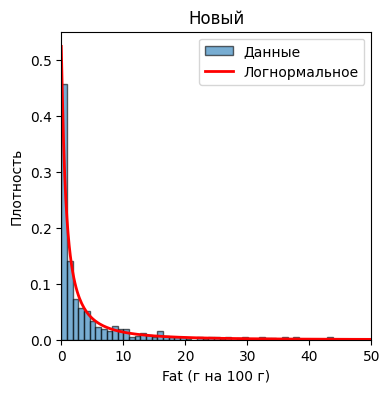

In [42]:
graphics.lognorm_graph(df_gen,"Fat", figsizz = (4,4),description = "Новый")

In [45]:
EDA.compare_EDAs(original = EDA.EDA_one_param(df,"Fat",description = "Старый",shut_graphics=shut_extra_info,shut_print=shut_extra_info),compared = EDA.EDA_one_param(df_gen,"Fat",description = "Новый",shut_graphics=shut_extra_info,shut_print=shut_extra_info))




============================ начинаем анализ по Fat ============================
=====================================Старый=====================================

<class 'pandas.core.series.Series'>
Index: 898 entries, 0 to 1672
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
898 non-null    float64
dtypes: float64(1)
memory usage: 46.3 KB



============================ начинаем анализ по Fat ============================
=====================================Новый======================================

<class 'pandas.core.series.Series'>
RangeIndex: 800 entries, 0 to 799
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
800 non-null    float64
dtypes: float64(1)
memory usage: 6.4 KB

=========================== сравнение EDA для 'Fat' ============================

Разница amount:          -98.00(-10.91%    ) (исходное/новое):(898/800)
Разница mean:            -0.29(-4.36%    )   (исходное/новое):(6.65/6.36)
Разница min_value:       0.00(/0(!!)    )   

По сути простейший код для генерации в три-четыре строчки приобрел две надстройки, отчего стал большим. идея такая: т.к. мы считаем параметры для ln(X), то у нас все нулевые значения будут либо отброшены, либо заменены - так у нас параметры будут сьезжать. Давайте сделаем надстройку, которая сначала посчитает долю нулей в исходном датафрейме(p0) и далее сгенерирует логнормальное распределение для числа записей, которое пропорционально меньше для p0. таким образом мы в конце к сгенерированной выборке с положительными числами просто добавим пропорциональное число нулей.
<br> <br> далее возникла проблема №2: оказывается, наши данные ограниченны, а логарифм - нет. по итогу получали значения мол в 100 гр продукта 1600 гр жира. невозможно. давайте тогда отбракуем все значения больше максимального значения от изначлаьного датасета. тогда происходит проблема: теперь у нас тело слишком тяжелое и квантили уезжают к началу. нас такое не устраивает, поэтому делаем так: если мы сгенерируем логнормальное распределение на всей длине и отрежем только нужную часть, то на ней все должно быть так, как в исходнике. главное- чтобы число записей было таким, каким нужно, а не меньше.
<br> т.е. если бы мы хотели например 200 значений, и из них 20 были больше предела (в нашем случае 100 гр) то мы бы их просто отбросили и у нас осталось бы всего 180 и тогда тело тяжелеет, а хвост легчает, а так быть не должно. ведь действительно - тело имеет веса под 200 записей и там хранятся все записи соответствующее этому числу, а вот хвост тоже имеет веса под 200 записей, но часть значений отрезана, поэтому происходит перевес тела.
<br><br> выкручиваемся мы из сей оказии следующим образом: давайте нагенерируем вместо 200 например 400 значений - чтоб в нашей области ну точно было необходимое 200 значений после выкидывания превышающих значений. т.к. после генерации мы каждый раз перемешиванием, то  пусть после всех перемешиваний, генераций и выкидываний у нас осталось 360 значений. мы просто берем первые 200 - ведь они ПЕРЕМЕШАНЫ! ну и получается тело взвешенно под 200 и имеет все свои записи и хвост взвешен  под 200 и имеет все его законные записи.




============================ начинаем анализ по Fat ============================
===================================из статьи====================================

<class 'pandas.core.series.Series'>
RangeIndex: 800 entries, 0 to 799
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
800 non-null    float64
dtypes: float64(1)
memory usage: 6.4 KB
Количество:               800
Среднее:                  7.25
Минимум:                  0.01
Максимум:                 71.35
Стандартное отклонение:   12.66
25-й перцентиль:          0.67
50-й перцентиль:          1.98
75-й перцентиль:          7.36
95-й перцентиль:          35.79
25-й перцентиль и 50-й перцентили отстоят друг от друга на 01.8% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 07.5% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 39.9% от всей длины отрезка


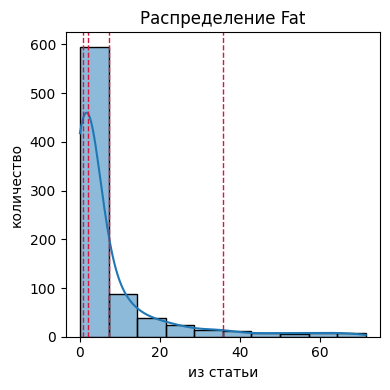




============================ начинаем анализ по Fat ============================
================================обратная функция================================

<class 'pandas.core.series.Series'>
RangeIndex: 800 entries, 0 to 799
Series name: Fat
Non-Null Count  Dtype  
--------------  -----  
800 non-null    float64
dtypes: float64(1)
memory usage: 6.4 KB
Количество:               800
Среднее:                  6.36
Минимум:                  0.0
Максимум:                 91.23
Стандартное отклонение:   12.73
25-й перцентиль:          0.26
50-й перцентиль:          1.45
75-й перцентиль:          5.94
95-й перцентиль:          32.76
25-й перцентиль и 50-й перцентили отстоят друг от друга на 01.3% от всей длины отрезка
50-й перцентиль и 75-й перцентили отстоят друг от друга на 04.9% от всей длины отрезка
75-й перцентиль и 95-й перцентили отстоят друг от друга на 29.4% от всей длины отрезка


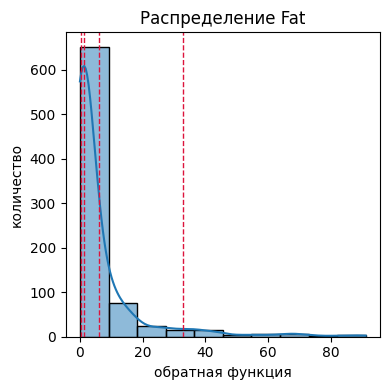


=========================== сравнение EDA для 'Fat' ============================

Разница amount:          0.00(0.00%    )     (исходное/новое):(800/800)
Разница mean:            -0.89(-12.28%    )  (исходное/новое):(7.25/6.36)
Разница min_value:       -0.01(-100.00%    ) (исходное/новое):(0.01/0.0)
Разница max_value:       19.88(27.86%    )   (исходное/новое):(71.35/91.23)
Разница std:             0.07(0.55%    )     (исходное/новое):(12.66/12.73)
Разница 25% quantile:    -0.41(-61.19%    )  (исходное/новое):(0.67/0.26)
Разница 50% quantile:    -0.53(-26.77%    )  (исходное/новое):(1.98/1.45)
Разница 75% quantile:    -1.42(-19.29%    )  (исходное/новое):(7.36/5.94)
Разница 95% quantile:    -3.03(-8.47%    )   (исходное/новое):(35.79/32.76)


In [44]:
# @markdown сравним два генератора между собой
EDA.compare_EDAs(original = EDA.EDA_one_param(dfF,"Fat",description = "из статьи"),compared = EDA.EDA_one_param(df_gen,"Fat",description = "обратная функция"))

**ВЫВОДЫ ПО ГЕНЕРАТОРАМ**
<br> квантили, конечно, также пляшут, что не может не досадовать. Предполагается, что такое поведение связанно с тем, что у нас есть низкожировые продукты и высокожировые ( см конец раздела "Гипотеза" ), а мы ловко пытаемся это все аппроксимировать под один плавный график - поэтому возможно, линейные методы могут давать хорошее попадание в среднее, максимальное и по "легким" квантилям - 10, 15, 25 и т.д.  пока идут низкожировые продукты. потом после разрыва между высокожировыми и низкожировыми показатели начинают сходить с ума - т.к. буквально монотоность больше не работает.
<br><br> что касательно сравнения двух генераторов: тут ситуация неоднозначная: "статейный" генератор хорошо справляется с телом распределения за счет размазывания и от этого же страдает на бинах с малой плотностью - за счет этого он  маловаспроизводим - ведь он может в ряде бинов завысить или занизить значения. как итог:  квантили от этого будут плясать.  В теле точки плотненько стоят и за счет этого они как бы в исходном датасете размазанны тоже равномерно. также статейный генератор лишь мимикрирует под реальный генератор - он по сути повторяет точки  на заданном диапазоне - он фундаментально в силу своего устройства не может выдать числа больше максимального значения из предоставленных.
<br> обратная функция же ведет себя по другому: просто по сути строит нормлаьное распрделение, параметры для которого получает из распределения из датасета а потом уже перестраивается в логнормальное. ну тут наоборот - эта модель слишком "независима" от исходной функции, от чего её гладкость не учитывает частичную кластеризацию продуктов на низкожировые и высокожировые.
<br> Генератор в данном случае тогда лучше выбирать под потребность, нет лучшего среди них

# [7] Выводы по датасету 2

У нас в данном датасете есть много выбросов (см самое начало датасета со значениями > 100), продукты никак не сгрупированны, просто набор записей. по сути, большинство переменных - не детерминируют друг друга, но имеют кореляции. единственная формула, которую мы знаем для всех компонентов, это то, что сумма их масс никогда не превышает 100 гр на 100 гр (может быть меньше, т.к. есть еще другие компоненты, что отсутствуют в настоящем датасете). В процессе изучения независимых переменных была сформулированна и доказана гипотеза. Затем было создано два генератора случайных чисел ( в данном случае для жира, одна вся "специализация" на определенном критерии меняется заменой соотв. строки в коде. Жир был выбран в качестве подопытного в силу скорости его написания.

# Литература



1.   [Перовскиты](https://clck.ru/3X9LTy)
2.   [Нутрициология](https://clck.ru/3X9LUh)
3.   [Взаимная информация](https://clck.ru/3X9LVB)
5.    [Метод обратной функции](https://clck.ru/3X9LXd)
6.   [Спирмен](https://clck.ru/3X9LZE)



# Немного о критериях
считаю выполнеными(или частично выполнеными) следующие критерии:

Критерии для КТвД:
- Структура исследования в документе
- Индексы разделов
- Скрытие кода
- Корректность масштабов на графиках и единиц измерения
- Единая стилистика для графиков
- Математические формулы в LaTeX. Единообразие математических формул (мало, конечно формул. **хотябы частично** )


Доп. Баллы
- Приведен и описан другой алгоритм генератора случайных чисел
- Список литературы
- За доп датасет **(хотя бы частично)**
- За каждое распределение **(логнормальное хотябы)**
- За табличное представление итоговых метрик **(хотябы частично)**
- исследование алгоритмов датчиков случайных чисел (типы распределений, где используется, сильные и слабые стороны, ссылки на алгоритмы, пример использования, ) за каждый 4 **(хотябы частично)**